In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo de gráficos
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Cargar datos (ojo: el notebook está en notebooks/, el CSV en data/)
df = pd.read_csv("../data/credit_risk_dataset.csv")

print("Shape:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

Shape: (32581, 12)

Columnas:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [3]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [4]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [5]:
nulos = df.isnull().sum().sort_values(ascending=False)
porcentaje = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
resumen_nulos = pd.DataFrame({"nulos": nulos, "porcentaje": porcentaje})
resumen_nulos[resumen_nulos["nulos"] > 0]

,nulos,porcentaje
loan_int_rate,3116,9.563856
person_emp_length,895,2.747000


loan_status
0    25473
1     7108
Name: count, dtype: int64

Proporción:
loan_status
0    0.782
1    0.218
Name: proportion, dtype: float64


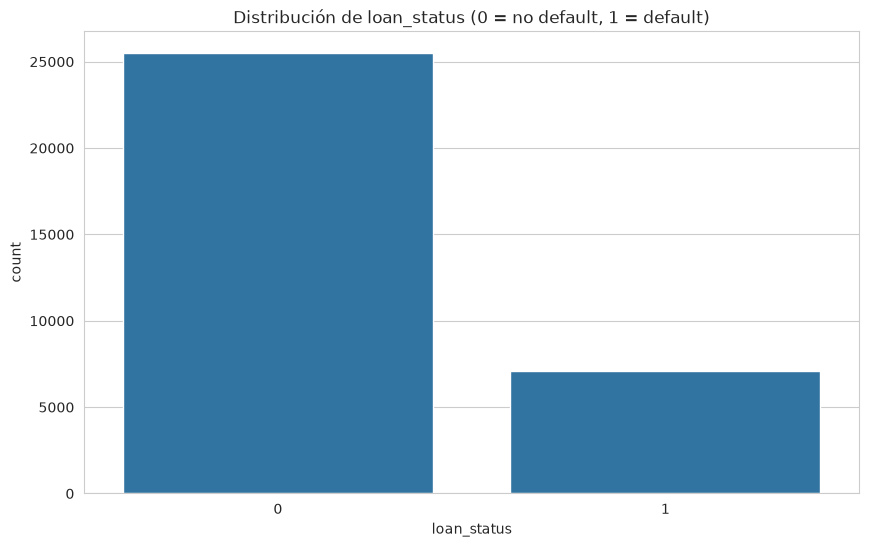

In [6]:
print(df["loan_status"].value_counts())
print("\nProporción:")
print(df["loan_status"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="loan_status")
plt.title("Distribución de loan_status (0 = no default, 1 = default)")
plt.show()

In [7]:
print("Duplicados:", df.duplicated().sum())

Duplicados: 165


In [8]:
# Variables numéricas candidatas a outliers
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate"]

df[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
person_age,32581.0,27.734600,6.348078,20.00,21.00,23.0,26.00,30.00,50.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,14400.00,38500.0,55000.00,79200.00,225200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,0.00,2.0,4.00,7.00,18.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,1000.00,5000.0,8000.00,12200.00,29800.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,5.42,7.9,10.99,13.47,18.62,23.22


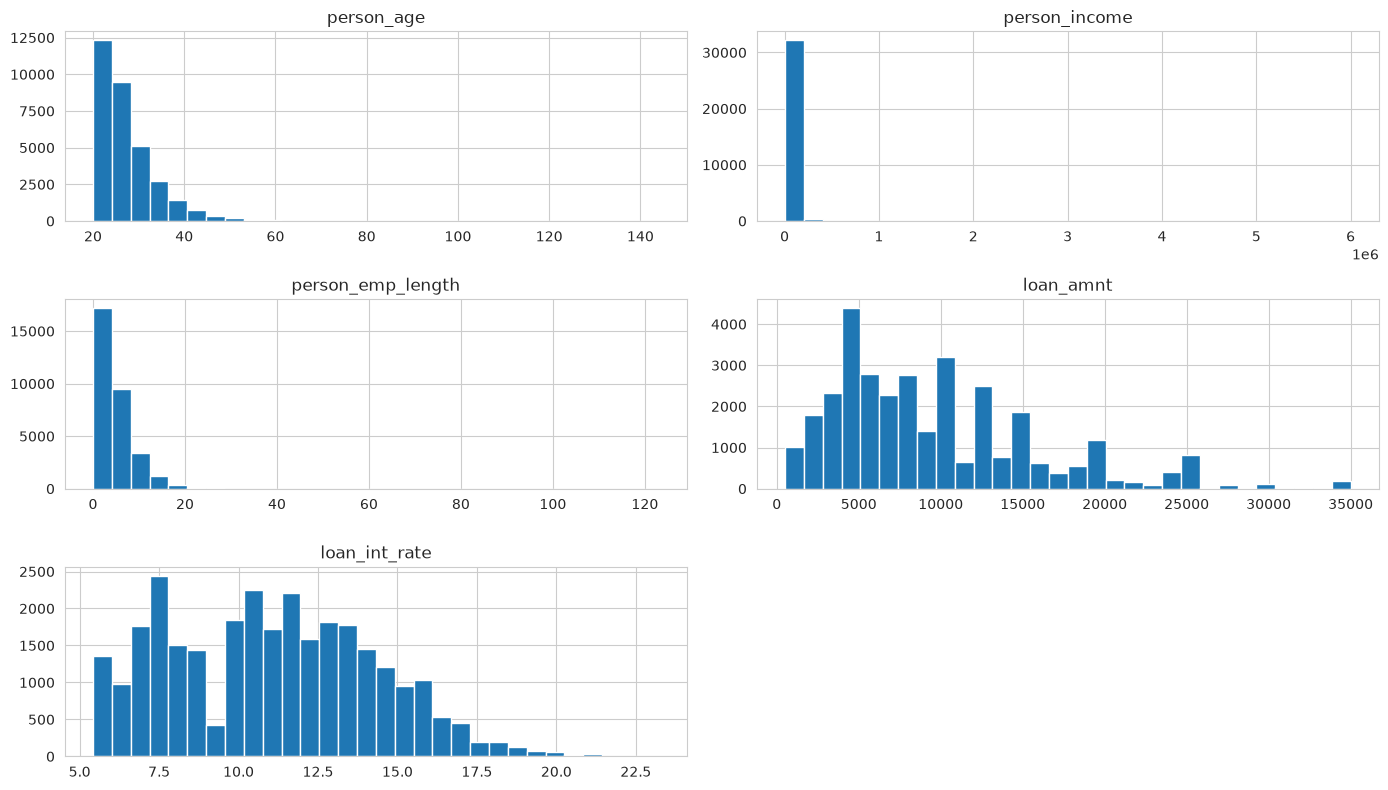

In [9]:
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

In [10]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- person_home_ownership ---
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

--- loan_intent ---
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

--- loan_grade ---
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

--- cb_person_default_on_file ---
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


# Situaciones más comunes en la Limpieza de Datos


### 2.1 DATOS FALTANTES (NULOS / NaN)


In [13]:
# Conteo y porcentaje de nulos por columna
nulos_total = df.isnull().sum()
nulos_pct = (df.isnull().sum() / len(df) * 100).round(2)

resumen_nulos = pd.DataFrame({
    "nulos": nulos_total,
    "porcentaje": nulos_pct,
    "tipo_dato": df.dtypes
}).sort_values("nulos", ascending=False)

# Mostrar solo las columnas que SÍ tienen nulos
print("=== COLUMNAS CON NULOS ===")
print(resumen_nulos[resumen_nulos["nulos"] > 0])
print(f"\nTotal de columnas con nulos: {(resumen_nulos['nulos'] > 0).sum()} de {len(df.columns)}")
print(f"Total de filas afectadas: {df.isnull().any(axis=1).sum()} de {len(df)} "
      f"({df.isnull().any(axis=1).sum()/len(df)*100:.2f}%)")


=== COLUMNAS CON NULOS ===
                   nulos  porcentaje tipo_dato
loan_int_rate       3116        9.56   float64
person_emp_length    895        2.75   float64

Total de columnas con nulos: 2 de 12
Total de filas afectadas: 3943 de 32581 (12.10%)


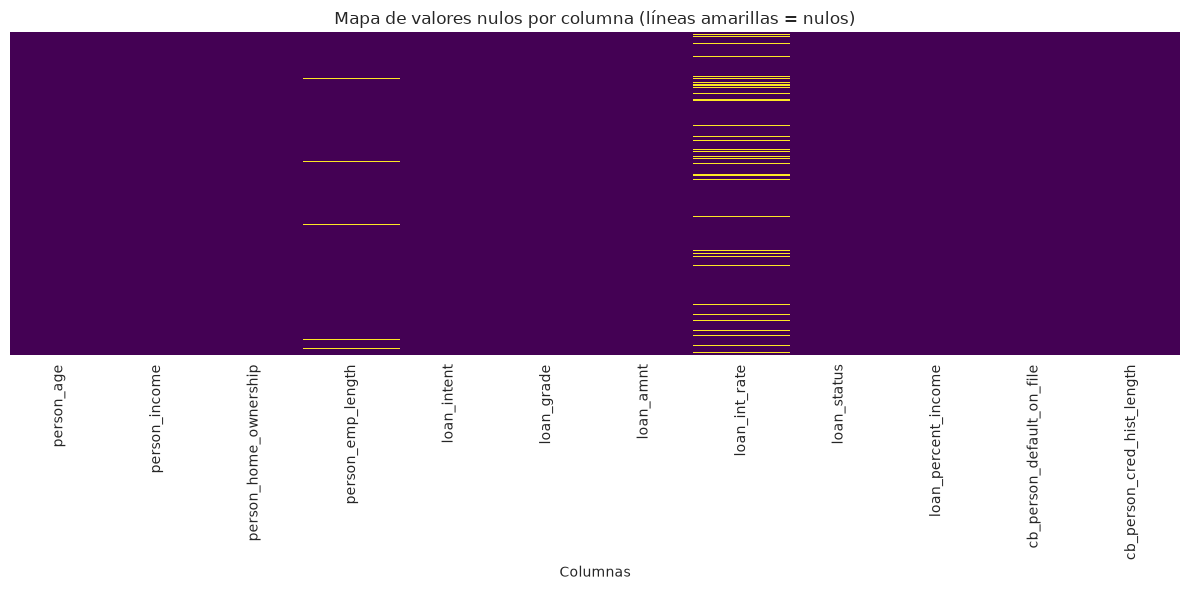

In [14]:
# Mapa visual de nulos
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de valores nulos por columna (líneas amarillas = nulos)")
plt.xlabel("Columnas")
plt.tight_layout()
plt.show()

In [15]:
# Comparar distribuciones entre filas con nulos vs sin nulos
# Ejemplo con loan_int_rate (que es la que más nulos suele tener)

col_con_nulos = "loan_int_rate"  # ajusta si tu columna más afectada es otra

print(f"=== ¿Los nulos en '{col_con_nulos}' dependen del perfil del cliente? ===\n")

df["tiene_nulo"] = df[col_con_nulos].isnull()

for col in ["loan_grade", "loan_intent", "person_home_ownership"]:
    print(f"\n--- {col} ---")
    print(df.groupby(col)["tiene_nulo"].mean().round(3).sort_values(ascending=False))

# Limpieza temporal de la columna auxiliar
df.drop(columns="tiene_nulo", inplace=True)

=== ¿Los nulos en 'loan_int_rate' dependen del perfil del cliente? ===


--- loan_grade ---
loan_grade
F    0.112
B    0.101
C    0.098
A    0.093
D    0.086
E    0.086
G    0.078
Name: tiene_nulo, dtype: float64

--- loan_intent ---
loan_intent
MEDICAL              0.102
VENTURE              0.099
DEBTCONSOLIDATION    0.098
EDUCATION            0.093
PERSONAL             0.092
HOMEIMPROVEMENT      0.087
Name: tiene_nulo, dtype: float64

--- person_home_ownership ---
person_home_ownership
OTHER       0.121
MORTGAGE    0.098
RENT        0.094
OWN         0.088
Name: tiene_nulo, dtype: float64


In [16]:
# ¿Hay filas que son 100% nulas?
filas_vacias = df.isnull().all(axis=1).sum()
print(f"Filas completamente vacías: {filas_vacias}")

# ¿Hay columnas completamente vacías?
cols_vacias = (df.isnull().sum() == len(df)).sum()
print(f"Columnas completamente vacías: {cols_vacias}")

Filas completamente vacías: 0
Columnas completamente vacías: 0


### 📝 Veredicto — Datos faltantes

**Hallazgos:**
- 2 columnas presentan valores nulos: `loan_int_rate` (9.56%) y `person_emp_length` (2.75%).
- En conjunto, 12.10% de las filas del dataset tienen al menos un nulo (3,943 de 32,581).
- No hay filas ni columnas completamente vacías.
- Los nulos en `loan_int_rate` son **aleatorios (MCAR)**: la tasa de nulos es prácticamente constante entre `loan_grade` (7.8%–11.2%), `loan_intent` (8.7%–10.2%) y `person_home_ownership` (8.8%–12.1%). No hay patrón sistemático por perfil de cliente.

**Decisión para el Día 2 (limpieza):**
- `person_emp_length`: imputar con **0** (asumiendo desempleado/sin historial laboral). Son solo 895 filas.
- `loan_int_rate`: imputar con la **mediana global**. Al ser MCAR, no se justifica una imputación por grupo y la mediana preserva la distribución central.
- **NO eliminar filas completas**: perderíamos 12% del dataset innecesariamente y las columnas afectadas no son críticas para el cálculo de la tasa de default.

**Justificación:** la imputación preserva el volumen de datos y no sesga la variable objetivo (`loan_status`), que es la métrica central del dashboard.

### 2.2 COLUMNAS IRRELEVANTES

In [18]:
# Ficha técnica de cada columna
inventario = pd.DataFrame({
    "columna": df.columns,
    "tipo": df.dtypes.values,
    "no_nulos": df.notnull().sum().values,
    "valores_unicos": df.nunique().values,
    "ejemplo": [df[c].dropna().iloc[0] if df[c].notnull().any() else None for c in df.columns]
})
inventario["pct_unicos"] = (inventario["valores_unicos"] / len(df) * 100).round(2)

print("=== INVENTARIO DE COLUMNAS ===")
print(inventario.to_string(index=False))

=== INVENTARIO DE COLUMNAS ===
                   columna    tipo  no_nulos  valores_unicos  ejemplo  pct_unicos
                person_age   int64     32581              58       22        0.18
             person_income   int64     32581            4295    59000       13.18
     person_home_ownership     str     32581               4     RENT        0.01
         person_emp_length float64     31686              36    123.0        0.11
               loan_intent     str     32581               6 PERSONAL        0.02
                loan_grade     str     32581               7        D        0.02
                 loan_amnt   int64     32581             753    35000        2.31
             loan_int_rate float64     29465             348    16.02        1.07
               loan_status   int64     32581               2        1        0.01
       loan_percent_income float64     32581              77     0.59        0.24
 cb_person_default_on_file     str     32581               2       

In [19]:
# Columnas con un solo valor único (constantes) → candidatas a eliminar
constantes = [c for c in df.columns if df[c].nunique() == 1]
print(f"Columnas constantes (1 único valor): {constantes if constantes else 'Ninguna'}")

# Columnas con muy pocos valores únicos (posible baja varianza)
baja_varianza = []
for c in df.columns:
    top_freq = df[c].value_counts(normalize=True).iloc[0]
    if top_freq > 0.95:  # >95% de los valores son el mismo
        baja_varianza.append((c, round(top_freq * 100, 2)))

print(f"\nColumnas con >95% de un mismo valor: {baja_varianza if baja_varianza else 'Ninguna'}")

Columnas constantes (1 único valor): Ninguna

Columnas con >95% de un mismo valor: Ninguna


In [20]:
# Una columna tipo ID suele tener: tantos únicos como filas (~100% únicos)
ids_sospechosos = inventario[
    (inventario["pct_unicos"] > 95) & 
    (inventario["tipo"] == "int64")
]

print("=== POSIBLES IDs (casi 100% únicos) ===")
print(ids_sospechosos if not ids_sospechosos.empty else "Ninguna columna parece un ID único.")

=== POSIBLES IDs (casi 100% únicos) ===
Ninguna columna parece un ID único.


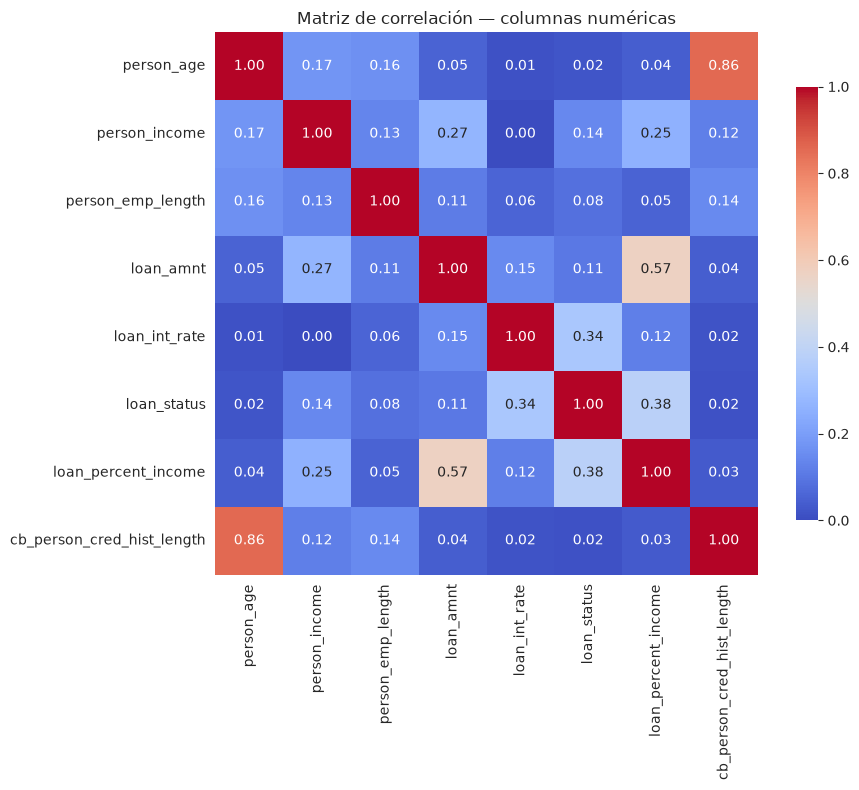


=== PARES CON CORRELACIÓN > 0.85 (posible redundancia) ===
  person_age ↔ cb_person_cred_hist_length: r = 0.859


In [21]:
# Columnas numéricas con correlación > 0.85 son redundantes entre sí
num_df = df.select_dtypes(include=["int64", "float64"])
corr_matrix = num_df.corr().abs()

# Mostrar la matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", 
            vmin=0, vmax=1, square=True, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación — columnas numéricas")
plt.tight_layout()
plt.show()

# Pares con correlación alta
print("\n=== PARES CON CORRELACIÓN > 0.85 (posible redundancia) ===")
pares_altos = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if corr_matrix.iloc[i, j] > 0.85:
            pares_altos.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                round(corr_matrix.iloc[i, j], 3)
            ))

if pares_altos:
    for c1, c2, r in pares_altos:
        print(f"  {c1} ↔ {c2}: r = {r}")
else:
    print("  Ninguno. Las columnas numéricas no son redundantes entre sí.")

In [22]:
# Reflexión de negocio: ¿qué columnas NO aportan al dashboard de riesgo?
# Este análisis es manual, pero esta celda lo documenta.

columnas_proyecto = {
    "person_age": "✅ Edad del solicitante — útil para segmentar riesgo por edad",
    "person_income": "✅ Ingreso anual — clave para evaluar capacidad de pago",
    "person_home_ownership": "✅ Tipo de vivienda — indicador de estabilidad",
    "person_emp_length": "✅ Años de empleo — indicador de estabilidad laboral",
    "loan_intent": "✅ Propósito del préstamo — segmenta el tipo de riesgo",
    "loan_grade": "✅ Calificación del préstamo (A-G) — construida por el banco",
    "loan_amnt": "✅ Monto del préstamo — variable central del negocio",
    "loan_int_rate": "✅ Tasa de interés — refleja el riesgo percibido",
    "loan_status": "✅ TARGET: 0 = no default, 1 = default",
    "loan_percent_income": "✅ Préstamo como % del ingreso — indicador de carga financiera",
    "cb_person_default_on_file": "✅ Default previo en buró de crédito — predictor fuerte",
    "cb_person_cred_hist_length": "✅ Historial crediticio (años) — mide madurez crediticia",
}

print("=== REVISIÓN DE VALOR DE NEGOCIO POR COLUMNA ===")
for col, valor in columnas_proyecto.items():
    print(f"{col:30} → {valor}")

=== REVISIÓN DE VALOR DE NEGOCIO POR COLUMNA ===
person_age                     → ✅ Edad del solicitante — útil para segmentar riesgo por edad
person_income                  → ✅ Ingreso anual — clave para evaluar capacidad de pago
person_home_ownership          → ✅ Tipo de vivienda — indicador de estabilidad
person_emp_length              → ✅ Años de empleo — indicador de estabilidad laboral
loan_intent                    → ✅ Propósito del préstamo — segmenta el tipo de riesgo
loan_grade                     → ✅ Calificación del préstamo (A-G) — construida por el banco
loan_amnt                      → ✅ Monto del préstamo — variable central del negocio
loan_int_rate                  → ✅ Tasa de interés — refleja el riesgo percibido
loan_status                    → ✅ TARGET: 0 = no default, 1 = default
loan_percent_income            → ✅ Préstamo como % del ingreso — indicador de carga financiera
cb_person_default_on_file      → ✅ Default previo en buró de crédito — predictor fuerte
cb_pe

### 📝 Veredicto — Columnas irrelevantes

**Hallazgos:**
- **Ninguna columna es constante**: todas tienen al menos 2 valores únicos.
- **Ninguna columna es un ID**: el máximo porcentaje de valores únicos es 13.18% (`person_income`).
- **Ninguna columna tiene baja varianza**: ningún valor se repite en >95% de las filas.
- **Una correlación alta detectada**: `person_age` ↔ `cb_person_cred_hist_length` (r = 0.859).
- Correlaciones moderadas relevantes para el negocio: `loan_percent_income` ↔ `loan_amnt` (0.57), `loan_status` ↔ `loan_percent_income` (0.38), `loan_status` ↔ `loan_int_rate` (0.34).

**Análisis de la correlación alta:**
Aunque `person_age` y `cb_person_cred_hist_length` están fuertemente correlacionadas, **NO son redundantes**. Miden dimensiones distintas:
- `person_age`: edad cronológica (para segmentar por rango etario).
- `cb_person_cred_hist_length`: años de historial crediticio (para segmentar por experiencia crediticia).

La diferencia entre ambas captura "cuán temprano empezó a construir historial" — información valiosa para evaluar riesgo. Eliminarlas implicaría perder un eje de segmentación.

**Decisión para el Día 2 (limpieza):**
- **Conservar las 12 columnas.** Ninguna es irrelevante, constante, redundante ni sin valor de negocio.
- Las correlaciones moderadas con `loan_status` (`loan_int_rate`, `loan_percent_income`) son señales predictivas a explotar en las vistas del Día 4, no motivos de eliminación.

**Justificación:** cada columna aporta valor analítico al dashboard. El objetivo es tener la mayor cantidad de ejes de segmentación disponibles para que el usuario pueda filtrar por perfil de cliente (edad, ingreso, vivienda, propósito, historial). Eliminar columnas empobrecería el dashboard sin beneficio real.

### 2.3 REGISTROS REPETIDOS (DUPLICADOS)

In [23]:
# Duplicados exactos (todas las columnas idénticas)
duplicados_exactos = df.duplicated().sum()
print(f"Duplicados exactos (filas 100% idénticas): {duplicados_exactos}")
print(f"Porcentaje del dataset: {duplicados_exactos / len(df) * 100:.2f}%")

Duplicados exactos (filas 100% idénticas): 165
Porcentaje del dataset: 0.51%


In [24]:
# Mostrar las primeras filas duplicadas para inspección visual
if duplicados_exactos > 0:
    duplicados_df = df[df.duplicated(keep=False)].sort_values(by=list(df.columns))
    print(f"Filas involucradas en duplicados (keep=False cuenta todas): {len(duplicados_df)}")
    print("\nPrimeros 10 duplicados:")
    display(duplicados_df.head(10))
else:
    print("No hay duplicados exactos para inspeccionar.")

Filas involucradas en duplicados (keep=False cuenta todas): 330

Primeros 10 duplicados:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [25]:
# Contar cuántos grupos únicos de duplicados existen y cuántas veces se repiten
if duplicados_exactos > 0:
    # Agrupar por todas las columnas y contar ocurrencias
    grupos = df.groupby(list(df.columns)).size().reset_index(name="conteo")
    grupos_dup = grupos[grupos["conteo"] > 1].sort_values("conteo", ascending=False)
    
    print(f"Total de grupos con más de 1 ocurrencia: {len(grupos_dup)}")
    print(f"Total de filas afectadas: {grupos_dup['conteo'].sum()}")
    print("\nDistribución de cuántas veces se repite cada grupo:")
    print(grupos_dup["conteo"].value_counts().sort_index())
    
    print("\nTop 5 grupos más repetidos:")
    display(grupos_dup.head())
else:
    print("Sin duplicados para agrupar.")

Total de grupos con más de 1 ocurrencia: 137
Total de filas afectadas: 274

Distribución de cuántas veces se repite cada grupo:
conteo
2    137
Name: count, dtype: int64

Top 5 grupos más repetidos:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,conteo
83,21,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4,2
101,21,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2,2
251,21,26000,RENT,5.0,DEBTCONSOLIDATION,A,6000,7.49,0,0.23,N,2,2
259,21,26400,RENT,5.0,PERSONAL,C,4750,12.23,0,0.18,N,3,2
275,21,27600,RENT,4.0,EDUCATION,A,7500,6.76,0,0.27,N,4,2


In [26]:
# Duplicados parciales: mismo perfil de cliente, distinto préstamo
# Columnas que definen "quién es el cliente"
cols_cliente = [
    "person_age", "person_income", "person_home_ownership",
    "person_emp_length", "cb_person_default_on_file", "cb_person_cred_hist_length"
]

dup_parciales = df.duplicated(subset=cols_cliente, keep=False).sum()
print(f"Filas con el mismo perfil de cliente (independiente del préstamo): {dup_parciales}")
print(f"Porcentaje del dataset: {dup_parciales / len(df) * 100:.2f}%")

# ¿Cuántos grupos de clientes repetidos hay?
grupos_cliente = df.groupby(cols_cliente).size().reset_index(name="solicitudes")
clientes_repetidos = grupos_cliente[grupos_cliente["solicitudes"] > 1]
print(f"\nClientes con más de una solicitud: {len(clientes_repetidos)}")
print(f"Solicitudes asociadas a clientes repetidos: {clientes_repetidos['solicitudes'].sum()}")

print("\nDistribución de solicitudes por cliente repetido:")
print(clientes_repetidos["solicitudes"].value_counts().sort_index())

Filas con el mismo perfil de cliente (independiente del préstamo): 6128
Porcentaje del dataset: 18.81%

Clientes con más de una solicitud: 2531
Solicitudes asociadas a clientes repetidos: 6033

Distribución de solicitudes por cliente repetido:
solicitudes
2     1945
3      361
4      133
5       56
6       17
7       13
8        2
9        3
12       1
Name: count, dtype: int64


In [27]:
# Comparar tasa de default entre filas únicas vs duplicadas
df["_es_duplicado"] = df.duplicated(keep=False)

tasa_default_unica = df[~df["_es_duplicado"]]["loan_status"].mean()
tasa_default_dup = df[df["_es_duplicado"]]["loan_status"].mean()

print(f"Tasa de default en filas únicas:   {tasa_default_unica:.4f} ({tasa_default_unica*100:.2f}%)")
print(f"Tasa de default en filas duplicadas: {tasa_default_dup:.4f} ({tasa_default_dup*100:.2f}%)")
print(f"Diferencia: {(tasa_default_dup - tasa_default_unica)*100:+.2f} puntos porcentuales")

# Limpieza temporal
df.drop(columns="_es_duplicado", inplace=True)

Tasa de default en filas únicas:   0.2192 (21.92%)
Tasa de default en filas duplicadas: 0.1152 (11.52%)
Diferencia: -10.41 puntos porcentuales


### 📝 Veredicto — Registros repetidos (Duplicados)

**Hallazgos:**
- **Duplicados exactos:** 165 filas (0.51%) distribuidas en 137 grupos de 2 ocurrencias cada uno. Son pares simples.
- **Duplicados parciales (mismo perfil de cliente):** 6,128 filas (18.81%) correspondientes a 2,531 clientes con múltiples solicitudes (hasta 12 en un caso).
- **Observación técnica:** los duplicados incluyen filas con NaN en `person_emp_length` o `loan_int_rate`; dos filas con el mismo patrón de nulos se consideran duplicadas.
- **⚠️ SESGO DETECTADO — hallazgo crítico:**
  - Tasa de default en filas únicas: **21.92%**
  - Tasa de default en filas duplicadas: **11.52%**
  - Diferencia: **-10.41 puntos porcentuales**
  - Los duplicados tienen aproximadamente la MITAD de tasa de default que las filas únicas. Esto NO es aleatorio: indica que la duplicación está correlacionada con la variable objetivo.

**Interpretación del sesgo:**
La duplicación no es aleatoria: las solicitudes que no entraron en default se duplicaron con mayor frecuencia que las que sí. Esto puede deberse a:
- Un sesgo en la generación/síntesis del dataset original.
- Un patrón de negocio donde clientes solventes solicitan múltiples productos.
- Un error de JOIN en el pipeline original del dataset.

Cualquiera sea la causa, este sesgo debe documentarse porque impacta el cálculo agregado de la tasa de default. La tasa "real" de la cartera podría estar entre 20% y 23%, no en 11% ni 30%.

**Decisión para el Día 2 (limpieza):**
- **Duplicados exactos:** eliminar con `df.drop_duplicates()` conservando la primera ocurrencia (~137 filas, 0.42%).
- **Duplicados parciales:** **conservar**, pero crear la columna `n_solicitudes_cliente` para medir cuántas filas comparten el mismo perfil.
- **Documentar el sesgo en el README** como una limitación del dataset y advertencia para la interpretación del dashboard.

**Justificación:**
Eliminar duplicados exactos es estándar. Conservar los duplicados parciales es correcto porque representan solicitudes legítimas. Sin embargo, el sesgo detectado debe quedar documentado para que el dashboard no dé una falsa impresión de precisión en la tasa de default.

### 2.4 VALORES EXTREMOS (OUTLIERS)

In [28]:
# Columnas numéricas continuas candidatas a outliers
num_cols = ["person_age", "person_income", "person_emp_length", 
            "loan_amnt", "loan_int_rate", "loan_percent_income", 
            "cb_person_cred_hist_length"]

# Percentiles extremos: 0.1%, 1%, 99%, 99.9%
percentiles = [0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]
desc = df[num_cols].describe(percentiles=percentiles).T
desc["rango"] = desc["max"] - desc["min"]
desc["asimetria"] = df[num_cols].skew().round(3)

print("=== ESTADÍSTICAS DESCRIPTIVAS CON PERCENTILES EXTREMOS ===")
display(desc[["min", "0.1%", "1%", "50%", "99%", "99.9%", "max", "rango", "asimetria"]])

=== ESTADÍSTICAS DESCRIPTIVAS CON PERCENTILES EXTREMOS ===


,min,0.1%,1%,50%,99%,99.9%,max,rango,asimetria
person_age,20.00,21.00,21.00,26.00,50.00,66.00,144.00,124.00,2.581
person_income,4000.00,8088.00,14400.00,55000.00,225200.00,648000.00,6000000.00,5996000.00,32.865
person_emp_length,0.00,0.00,0.00,4.00,18.00,25.00,123.00,123.00,2.614
loan_amnt,500.00,1000.00,1000.00,8000.00,29800.00,35000.00,35000.00,34500.00,1.192
loan_int_rate,5.42,5.42,5.42,10.99,18.62,20.89,23.22,17.80,0.209
loan_percent_income,0.00,0.01,0.02,0.15,0.50,0.63,0.83,0.83,1.065
cb_person_cred_hist_length,2.00,2.00,2.00,4.00,17.00,29.00,30.00,28.00,1.662


Qué buscar:

Asimetría > 1 o < -1 → distribución sesgada, típico candidato a outliers.

Diferencia grande entre 99.9% y max → hay valores extremos aislados en la cola.

In [29]:
def detectar_outliers_iqr(df, columna, multiplicador=1.5):
    """Devuelve los valores atípicos según IQR."""
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    li = Q1 - multiplicador * IQR
    ls = Q3 + multiplicador * IQR
    outliers = df[(df[columna] < li) | (df[columna] > ls)][columna]
    return {
        "columna": columna,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "limite_inf": round(li, 2),
        "limite_sup": round(ls, 2),
        "n_outliers": len(outliers),
        "pct": round(len(outliers) / len(df) * 100, 2)
    }

# Aplicar a todas las numéricas
resultados_iqr = pd.DataFrame([detectar_outliers_iqr(df, c) for c in num_cols])
resultados_iqr = resultados_iqr.sort_values("n_outliers", ascending=False)

print("=== OUTLIERS SEGÚN IQR (1.5×) ===")
print(resultados_iqr.to_string(index=False))

=== OUTLIERS SEGÚN IQR (1.5×) ===
                   columna       Q1       Q3      IQR  limite_inf  limite_sup  n_outliers  pct
                 loan_amnt  5000.00 12200.00  7200.00    -5800.00    23000.00        1689 5.18
                person_age    23.00    30.00     7.00       12.50       40.50        1494 4.59
             person_income 38500.00 79200.00 40700.00   -22550.00   140250.00        1484 4.55
cb_person_cred_hist_length     3.00     8.00     5.00       -4.50       15.50        1142 3.51
         person_emp_length     2.00     7.00     5.00       -5.50       14.50         853 2.62
       loan_percent_income     0.09     0.23     0.14       -0.12        0.44         651 2.00
             loan_int_rate     7.90    13.47     5.57       -0.46       21.83           6 0.02


In [31]:
from scipy import stats

def detectar_outliers_zscore(df, columna, umbral=3):
    """Devuelve los valores atípicos según Z-score (|z| > umbral)."""
    z = np.abs(stats.zscore(df[columna].dropna()))
    n_outliers = (z > umbral).sum()
    return {
        "columna": columna,
        "n_outliers": n_outliers,
        "pct": round(n_outliers / len(df) * 100, 2)
    }

resultados_z = pd.DataFrame([detectar_outliers_zscore(df, c) for c in num_cols])
resultados_z = resultados_z.sort_values("n_outliers", ascending=False)

print("=== OUTLIERS SEGÚN Z-SCORE (|z| > 3) ===")
print(resultados_z.to_string(index=False))

=== OUTLIERS SEGÚN Z-SCORE (|z| > 3) ===
                   columna  n_outliers  pct
                person_age         558 1.71
                 loan_amnt         337 1.03
       loan_percent_income         336 1.03
         person_emp_length         321 0.99
cb_person_cred_hist_length         284 0.87
             person_income         233 0.72
             loan_int_rate          38 0.12


In [33]:
# REGLAS DE NEGOCIO — VALORES IMPOSIBLES

print("=== VALORES IMPOSIBLES SEGÚN LÓGICA DE NEGOCIO ===\n")

# 1. Edad mayor a 100 años (récord mundial: 122, pero para crédito es irreal)
print(f"1. person_age > 100: {(df['person_age'] > 100).sum()} filas")
print(f"   Valores únicos: {sorted(df[df['person_age'] > 100]['person_age'].unique())}")

# 2. Historial laboral mayor a la edad - 14 (asumiendo edad mínima laboral: 14 años)
print(f"\n2. person_emp_length > person_age - 14: "
      f"{(df['person_emp_length'] > df['person_age'] - 14).sum()} filas")

# 3. Historial crediticio mayor a la edad - 18
print(f"3. cb_person_cred_hist_length > person_age - 18: "
      f"{(df['cb_person_cred_hist_length'] > df['person_age'] - 18).sum()} filas")

# 4. Ingreso anual = 0 o negativo (imposible para solicitar crédito)
print(f"4. person_income <= 0: {(df['person_income'] <= 0).sum()} filas")

# 5. Tasa de interés fuera de rango razonable (0% - 50%)
print(f"5. loan_int_rate < 0 o > 50: "
      f"{((df['loan_int_rate'] < 0) | (df['loan_int_rate'] > 50)).sum()} filas")

# 6. loan_percent_income > 1 (más del 100% del ingreso)
print(f"6. loan_percent_income > 1: {(df['loan_percent_income'] > 1).sum()} filas")

=== VALORES IMPOSIBLES SEGÚN LÓGICA DE NEGOCIO ===

1. person_age > 100: 5 filas
   Valores únicos: [np.int64(123), np.int64(144)]

2. person_emp_length > person_age - 14: 2 filas
3. cb_person_cred_hist_length > person_age - 18: 781 filas
4. person_income <= 0: 0 filas
5. loan_int_rate < 0 o > 50: 0 filas
6. loan_percent_income > 1: 0 filas


Interpretación esperada:

person_age con valores absurdos (144 años).

person_emp_length con 123 años (imposible: la persona tendría que haber empezado a trabajar a los -100 años).

cb_person_cred_hist_length incongruente con la edad.

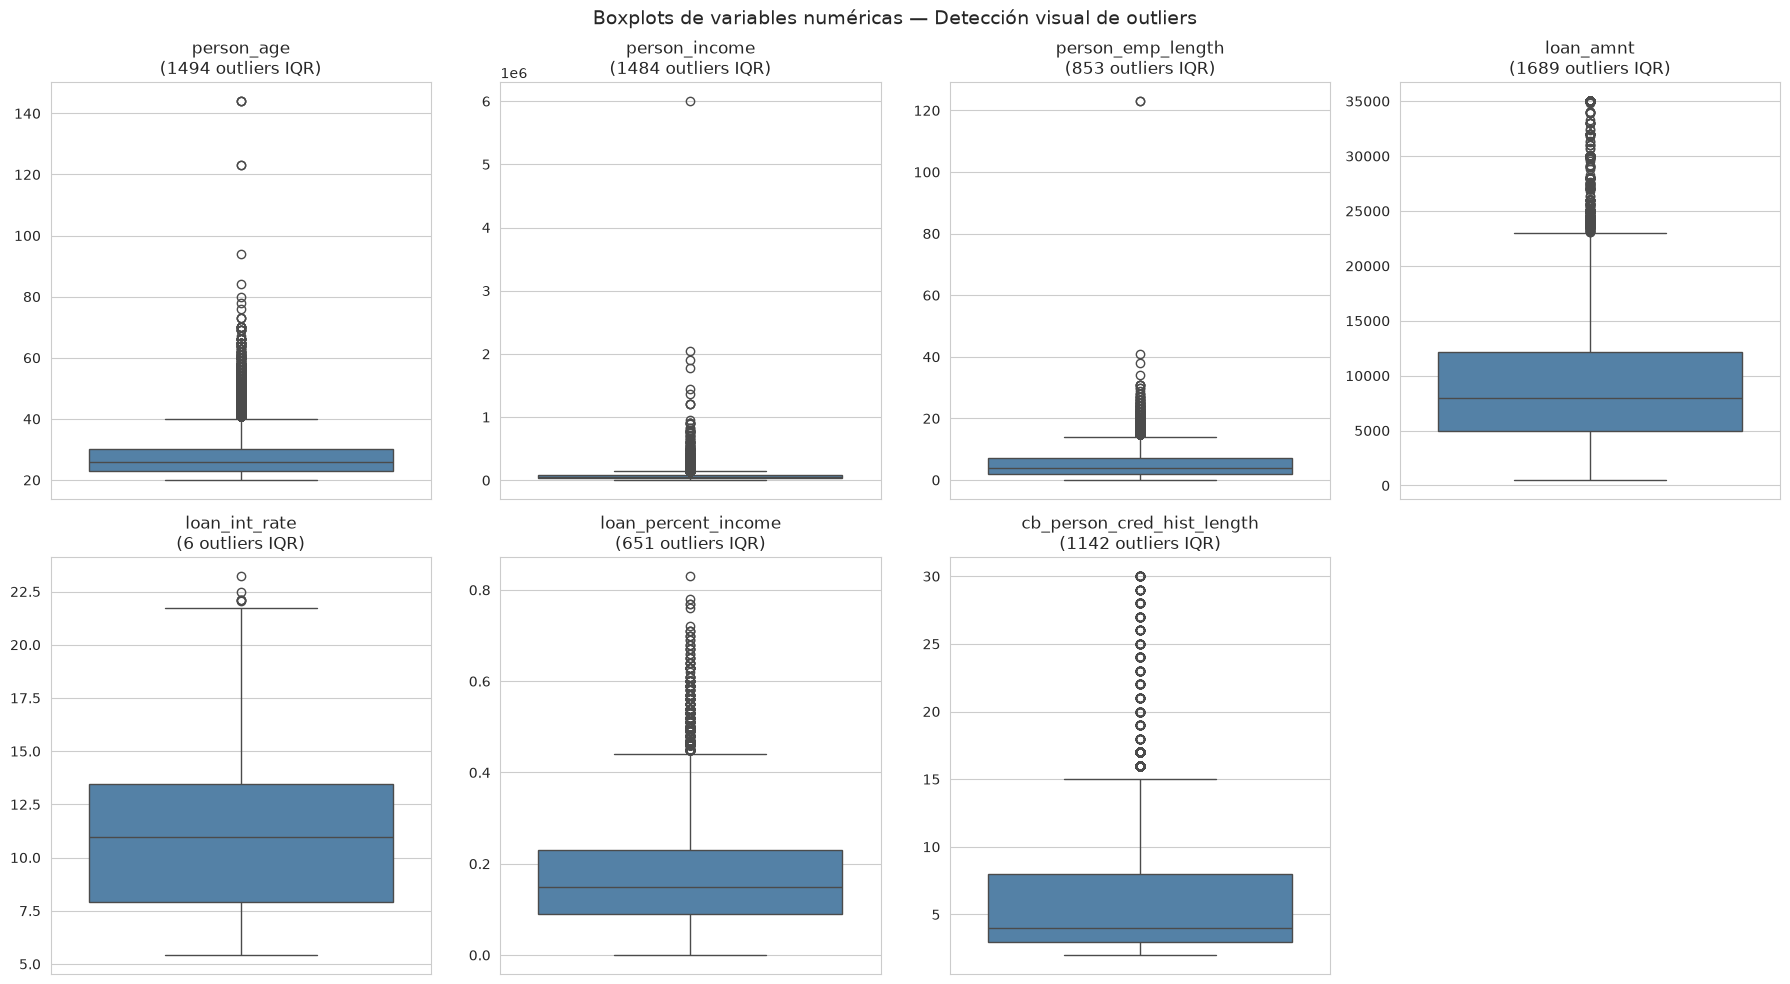

In [34]:
# Boxplots de las variables con más outliers
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col}\n({resultados_iqr.loc[resultados_iqr['columna']==col, 'n_outliers'].values[0]} outliers IQR)")
    axes[i].set_ylabel("")

# Ocultar el último eje si sobran
if len(num_cols) < len(axes):
    for j in range(len(num_cols), len(axes)):
        axes[j].set_visible(False)

plt.suptitle("Boxplots de variables numéricas — Detección visual de outliers", fontsize=14)
plt.tight_layout()
plt.show()

In [35]:
# Los 10 valores más extremos por columna
print("=== TOP 10 VALORES EXTREMOS POR COLUMNA ===\n")

for col in ["person_age", "person_income", "person_emp_length"]:
    print(f"\n--- {col} ---")
    print(f"Top 10 más altos: {sorted(df[col].dropna().nlargest(10).unique())}")
    print(f"Top 10 más bajos: {sorted(df[col].dropna().nsmallest(10).unique())}")

=== TOP 10 VALORES EXTREMOS POR COLUMNA ===


--- person_age ---
Top 10 más altos: [np.int64(76), np.int64(78), np.int64(80), np.int64(84), np.int64(94), np.int64(123), np.int64(144)]
Top 10 más bajos: [np.int64(20)]

--- person_income ---
Top 10 más altos: [np.int64(948000), np.int64(1200000), np.int64(1362000), np.int64(1440000), np.int64(1782000), np.int64(1900000), np.int64(2039784), np.int64(6000000)]
Top 10 más bajos: [np.int64(4000), np.int64(4080), np.int64(4200), np.int64(4800), np.int64(4888), np.int64(5000)]

--- person_emp_length ---
Top 10 más altos: [np.float64(30.0), np.float64(31.0), np.float64(34.0), np.float64(38.0), np.float64(41.0), np.float64(123.0)]
Top 10 más bajos: [np.float64(0.0)]


### 📝 Veredicto — Valores extremos (Outliers)

**Hallazgos estadísticos:**
- `person_income` tiene asimetría extrema (32.87) y valores hasta $6,000,000, muy alejados del percentil 99.9% ($648,000).
- `person_age` (asimetría 2.58) y `person_emp_length` (asimetría 2.61) presentan colas largas con valores imposibles.
- `loan_int_rate` está prácticamente limpio (solo 6 outliers IQR, 38 en Z-score), con distribución casi simétrica.

**Hallazgos por reglas de negocio (críticos):**
- **`person_age > 100`: 5 filas** con edades de 123 y 144 años → **imposibles físicamente**.
- **`person_emp_length > person_age - 14`: 2 filas** → la persona habría empezado a trabajar antes de nacer.
- **`cb_person_cred_hist_length > person_age - 18`: 781 filas (2.4%)** → historial crediticio imposible de haber construido a esa edad.
- `person_income <= 0`, `loan_int_rate` fuera de rango, `loan_percent_income > 1`: **0 casos**. Estas reglas se cumplen.

**Análisis:**
Hay que distinguir dos categorías de outliers:
1. **Outliers plausibles** (ej. ingresos altos de $1M, edades de 76-84 años, créditos de $35K): son inusuales pero reales. **Conservar**.
2. **Outliers imposibles** (ej. edad 144, historial laboral 123 años, historial crediticio mayor que la edad adulta): son **errores** y deben tratarse quirúrgicamente.

Los 781 casos con historial crediticio inconsistente reflejan que el generador del dataset no impuso correlación entre edad e historial. Es una limitación conocida del dataset.

**Decisión para el Día 2 (limpieza):**
- **Eliminar** filas con `person_age > 100` (5 filas, 0.015%).
- **Eliminar** filas con `person_emp_length > person_age - 14` (2 filas).
- **Tratar** los 781 casos de `cb_person_cred_hist_length` inconsistente: **cap al máximo plausible** = `min(cred_hist_length, person_age - 18)` en lugar de eliminar, para no perder 2.4% del dataset.
- **Conservar** outliers plausibles (ingresos altos, créditos grandes, edades mayores).
- **No transformar** variables para el dashboard (BI no requiere log), pero anotar en el README que `person_income` tiene asimetría extrema y podría beneficiarse de transformación logarítmica en modelos.

**Justificación:**
Eliminar outliers imposibles limpia la calidad del dashboard sin sacrificar volumen. Conservar outliers plausibles preserva señal de negocio. El cap en historial crediticio corrige la inconsistencia sin perder datos.

### 2.5 ERRORES TIPOGRÁFICOS EN CATEGÓRICAS

Qué buscar:

Diferencias de mayúsculas/minúsculas: "RENT" vs "rent".

Espacios al inicio/final: "RENT " vs "RENT".

Typos: "MORTGAG", "PERSONAL ", "HOME IMPROVEMENT" vs "HOMEIMPROVEMENT".

In [37]:

cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

print("=== VALORES ÚNICOS POR COLUMNA CATEGÓRICA ===\n")

for col in cat_cols:
    print(f"\n--- {col} ({df[col].nunique()} únicos) ---")
    print(df[col].value_counts())
    print(f"Valores únicos: {sorted(df[col].dropna().unique())}")

=== VALORES ÚNICOS POR COLUMNA CATEGÓRICA ===


--- person_home_ownership (4 únicos) ---
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64
Valores únicos: ['MORTGAGE', 'OTHER', 'OWN', 'RENT']

--- loan_intent (6 únicos) ---
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64
Valores únicos: ['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL', 'PERSONAL', 'VENTURE']

--- loan_grade (7 únicos) ---
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64
Valores únicos: ['A', 'B', 'C', 'D', 'E', 'F', 'G']

--- cb_person_default_on_file (2 únicos) ---
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64
Valores únicos: ['N', 'Y']


In [38]:
print("=== ESPACIOS OCULTOS ===\n")

for col in cat_cols:
    tiene_espacios = df[col].dropna().astype(str).str.strip() != df[col].dropna().astype(str)
    n_con_espacios = tiene_espacios.sum()
    if n_con_espacios > 0:
        print(f"⚠️ {col}: {n_con_espacios} valores con espacios extra")
        print(f"   Ejemplos: {df[col].dropna()[tiene_espacios].unique()[:5]}")
    else:
        print(f"✅ {col}: sin espacios ocultos")

=== ESPACIOS OCULTOS ===

✅ person_home_ownership: sin espacios ocultos
✅ loan_intent: sin espacios ocultos
✅ loan_grade: sin espacios ocultos
✅ cb_person_default_on_file: sin espacios ocultos


In [39]:
print("=== INCONSISTENCIA DE MAYÚSCULAS/MINÚSCULAS ===\n")

for col in cat_cols:
    # Contar cuántos valores únicos quedan si normalizamos a lower
    originales = df[col].dropna().nunique()
    normalizados = df[col].dropna().str.lower().nunique()
    
    if originales != normalizados:
        print(f"⚠️ {col}: {originales} valores originales → {normalizados} al normalizar (hay variantes)")
    else:
        print(f"✅ {col}: consistente (todos los valores usan el mismo formato)")

=== INCONSISTENCIA DE MAYÚSCULAS/MINÚSCULAS ===

✅ person_home_ownership: consistente (todos los valores usan el mismo formato)
✅ loan_intent: consistente (todos los valores usan el mismo formato)
✅ loan_grade: consistente (todos los valores usan el mismo formato)
✅ cb_person_default_on_file: consistente (todos los valores usan el mismo formato)


In [40]:
print("=== VARIANTES DEL MISMO VALOR (similitud) ===\n")

for col in cat_cols:
    # Quitar espacios, normalizar a lower, y comparar
    valores = df[col].dropna().unique()
    normalizados = {}
    for v in valores:
        key = str(v).strip().lower().replace("-", "").replace("_", "").replace(" ", "")
        normalizados.setdefault(key, []).append(v)
    
    # Buscar claves con más de un valor original (implica variantes)
    variantes = {k: v for k, v in normalizados.items() if len(v) > 1}
    
    if variantes:
        print(f"⚠️ {col} tiene posibles variantes:")
        for k, v in variantes.items():
            print(f"   {v}")
    else:
        print(f"✅ {col}: sin variantes detectadas")

=== VARIANTES DEL MISMO VALOR (similitud) ===

✅ person_home_ownership: sin variantes detectadas
✅ loan_intent: sin variantes detectadas
✅ loan_grade: sin variantes detectadas
✅ cb_person_default_on_file: sin variantes detectadas


In [41]:
print("=== FRECUENCIA DE CADA CATEGORÍA ===\n")

for col in cat_cols:
    print(f"\n--- {col} ---")
    freq = df[col].value_counts(normalize=True).round(4) * 100
    for val, pct in freq.items():
        print(f"  {val:20} → {pct:6.2f}%")

=== FRECUENCIA DE CADA CATEGORÍA ===


--- person_home_ownership ---
  RENT                 →  50.48%
  MORTGAGE             →  41.26%
  OWN                  →   7.93%
  OTHER                →   0.33%

--- loan_intent ---
  EDUCATION            →  19.81%
  MEDICAL              →  18.63%
  VENTURE              →  17.55%
  PERSONAL             →  16.95%
  DEBTCONSOLIDATION    →  16.00%
  HOMEIMPROVEMENT      →  11.06%

--- loan_grade ---
  A                    →  33.08%
  B                    →  32.08%
  C                    →  19.82%
  D                    →  11.13%
  E                    →   2.96%
  F                    →   0.74%
  G                    →   0.20%

--- cb_person_default_on_file ---
  N                    →  82.37%
  Y                    →  17.63%


### 📝 Veredicto — Errores tipográficos en variables categóricas

**Hallazgos:**
- **Valores únicos por columna:** `person_home_ownership` (4), `loan_intent` (6), `loan_grade` (7), `cb_person_default_on_file` (2).
- **Espacios ocultos (leading/trailing):** ninguna columna afectada.
- **Inconsistencias de mayúsculas/minúsculas:** ninguna columna afectada. Todos los valores están en mayúsculas.
- **Variantes del mismo valor:** ninguna. No hay casos como `"HOME IMPROVEMENT"` vs `"HOMEIMPROVEMENT"`.
- **Categorías minoritarias detectadas:** `person_home_ownership = OTHER` (0.33%), `loan_grade = F` (0.74%) y `loan_grade = G` (0.20%). Se abordarán en la Situación 10.

**Observación adicional:** `loan_grade` es una **escala ordinal** (A mejor, G peor), no nominal. En el dashboard y en las vistas SQL se debe preservar el orden A→G explícitamente, no el alfabético.

**Decisión para el Día 2 (limpieza):**
- **Sin acciones necesarias.** Las 4 columnas categóricas están consistentes y limpias.
- Documentar el orden ordinal de `loan_grade` para las vistas de BigQuery.

**Justificación:**
Un dataset con categorías inconsistentes genera duplicación en agregaciones SQL y confusión en el dashboard. Auditar typos temprano evita sorpresas al construir las vistas. En este caso, el dataset ya viene limpio en este aspecto, lo cual confirma que el generador aplicó reglas de estandarización.

### 2.6 TIPOS DE DATOS INCORRECTOS ("El Falso Texto")

Qué buscar:

Columnas numéricas que aparezcan como object o str → ⚠️ problema.

Columnas categóricas que aparezcan como int64 → puede ser correcto (ej. un flag 0/1) o problemático (ej. IDs).

In [42]:

print("=== TIPOS DE DATOS ACTUALES ===\n")

tipos_df = pd.DataFrame({
    "columna": df.columns,
    "tipo_pandas": df.dtypes.astype(str).values,
    "ejemplo_valor": [df[c].dropna().iloc[0] if df[c].notnull().any() else None for c in df.columns],
    "tipo_python": [type(df[c].dropna().iloc[0]).__name__ if df[c].notnull().any() else None for c in df.columns]
})

display(tipos_df)

=== TIPOS DE DATOS ACTUALES ===



,columna,tipo_pandas,ejemplo_valor,tipo_python
0,person_age,int64,22,int64
1,person_income,int64,59000,int64
2,person_home_ownership,str,RENT,str
3,person_emp_length,float64,123.0,float64
4,loan_intent,str,PERSONAL,str
5,loan_grade,str,D,str
6,loan_amnt,int64,35000,int64
7,loan_int_rate,float64,16.02,float64
8,loan_status,int64,1,int64
9,loan_percent_income,float64,0.59,float64


In [43]:
print("=== DETECCIÓN DE FALSO TEXTO ===\n")

# Para cada columna tipo texto, intentar convertir a numérico
# Si TODOS los valores se pueden convertir, entonces era un "falso texto"
for col in df.select_dtypes(include=["object", "str"]).columns:
    serie = df[col].dropna()
    
    # Intentar convertir a numérico
    try:
        convertida = pd.to_numeric(serie, errors="coerce")
        n_convertibles = convertida.notnull().sum()
        pct_convertibles = n_convertibles / len(serie) * 100
        
        if pct_convertibles > 90:
            print(f"🚩 {col}: {pct_convertibles:.2f}% de valores son numéricos disfrazados de texto")
            print(f"   Ejemplos: {serie.head(3).tolist()}")
        elif pct_convertibles > 50:
            print(f"⚠️ {col}: {pct_convertibles:.2f}% convertibles (revisar)")
        else:
            print(f"✅ {col}: texto genuino ({pct_convertibles:.2f}% convertibles)")
    except Exception as e:
        print(f"⚠️ {col}: no se pudo analizar ({e})")

=== DETECCIÓN DE FALSO TEXTO ===

✅ person_home_ownership: texto genuino (0.00% convertibles)
✅ loan_intent: texto genuino (0.00% convertibles)
✅ loan_grade: texto genuino (0.00% convertibles)
✅ cb_person_default_on_file: texto genuino (0.00% convertibles)


Interpretación:

90% convertibles → falso texto (¡hay que corregir!).

50-90% → mixto, revisar caso por caso.

<50% → texto genuino, OK.

In [44]:
print("=== ¿ALGÚN NUMÉRICO DEBERÍA SER CATEGÓRICO? ===\n")

# Columnas numéricas con pocos valores únicos (<20) pueden ser flags o categorías
for col in df.select_dtypes(include=["int64", "float64"]).columns:
    n_unicos = df[col].nunique()
    if n_unicos < 20:
        print(f"⚠️ {col}: {n_unicos} valores únicos → {sorted(df[col].dropna().unique())}")
        print(f"   ¿Es categórico o un flag binario?")
    else:
        print(f"✅ {col}: {n_unicos} valores únicos (numérico continuo/discreto legítimo)")

=== ¿ALGÚN NUMÉRICO DEBERÍA SER CATEGÓRICO? ===

✅ person_age: 58 valores únicos (numérico continuo/discreto legítimo)
✅ person_income: 4295 valores únicos (numérico continuo/discreto legítimo)
✅ person_emp_length: 36 valores únicos (numérico continuo/discreto legítimo)
✅ loan_amnt: 753 valores únicos (numérico continuo/discreto legítimo)
✅ loan_int_rate: 348 valores únicos (numérico continuo/discreto legítimo)
⚠️ loan_status: 2 valores únicos → [np.int64(0), np.int64(1)]
   ¿Es categórico o un flag binario?
✅ loan_percent_income: 77 valores únicos (numérico continuo/discreto legítimo)
✅ cb_person_cred_hist_length: 29 valores únicos (numérico continuo/discreto legítimo)


In [45]:
print("=== VERIFICACIONES ESPECÍFICAS ===\n")

# 1. ¿Hay columnas con símbolos de moneda o separadores?
for col in df.select_dtypes(include=["object", "str"]).columns:
    serie = df[col].dropna().astype(str)
    tiene_simbolos = serie.str.contains(r"[$€£,%]", regex=True).any()
    if tiene_simbolos:
        print(f"⚠️ {col}: contiene símbolos ($, €, £, %, ,)")
        print(f"   Ejemplos: {serie[serie.str.contains(r'[$€£,%]', regex=True)].head(3).tolist()}")
    else:
        print(f"✅ {col}: sin símbolos de moneda ni separadores")

print()

# 2. ¿Hay columnas con valores como "0" y "N" mezclados (bool ambiguo)?
for col in df.select_dtypes(include=["object", "str"]).columns:
    valores = set(df[col].dropna().astype(str).unique())
    if valores.intersection({"0", "1", "true", "false", "True", "False"}):
        print(f"⚠️ {col}: contiene valores tipo bool ambiguos: {valores}")
    else:
        print(f"✅ {col}: sin valores bool ambiguos")

=== VERIFICACIONES ESPECÍFICAS ===

✅ person_home_ownership: sin símbolos de moneda ni separadores
✅ loan_intent: sin símbolos de moneda ni separadores
✅ loan_grade: sin símbolos de moneda ni separadores
✅ cb_person_default_on_file: sin símbolos de moneda ni separadores

✅ person_home_ownership: sin valores bool ambiguos
✅ loan_intent: sin valores bool ambiguos
✅ loan_grade: sin valores bool ambiguos
✅ cb_person_default_on_file: sin valores bool ambiguos


In [46]:
print("=== CONVERSIONES SUGERIDAS PARA EL DÍA 2 ===\n")

conversiones = []

for col in df.columns:
    tipo_actual = str(df[col].dtype)
    
    # Si es texto pero parece numérico
    if tipo_actual in ["object", "str"]:
        try:
            serie = df[col].dropna()
            convertida = pd.to_numeric(serie, errors="coerce")
            if convertida.notnull().sum() / len(serie) > 0.9:
                conversiones.append((col, tipo_actual, "numérico", "Falso texto detectado"))
        except:
            pass

# Reportar
if conversiones:
    for col, actual, sugerido, razon in conversiones:
        print(f"⚠️ {col}: {actual} → {sugerido} ({razon})")
else:
    print("✅ No hay conversiones necesarias. Los tipos actuales son correctos.")
    print("\nResumen de tipos por columna:")
    for col in df.columns:
        print(f"  {col:35} → {df[col].dtype}")

=== CONVERSIONES SUGERIDAS PARA EL DÍA 2 ===

✅ No hay conversiones necesarias. Los tipos actuales son correctos.

Resumen de tipos por columna:
  person_age                          → int64
  person_income                       → int64
  person_home_ownership               → str
  person_emp_length                   → float64
  loan_intent                         → str
  loan_grade                          → str
  loan_amnt                           → int64
  loan_int_rate                       → float64
  loan_status                         → int64
  loan_percent_income                 → float64
  cb_person_default_on_file           → str
  cb_person_cred_hist_length          → int64


### 📝 Veredicto — Tipos de datos incorrectos

**Hallazgos:**
- **Falso texto (números guardados como string):** ninguno. Las 4 columnas categóricas son texto genuino (0% convertibles a numérico).
- **Numéricos con apariencia categórica:** `loan_status` (2 valores: 0/1) es un flag binario, correcto como `int64`. Se tratará como categoría en el dashboard.
- **Símbolos de moneda o separadores:** ninguno.
- **Valores bool ambiguos:** ninguno.
- **Tipos actuales:** 100% coherentes con la naturaleza de cada variable.
  - Numéricas: `person_age`, `person_income`, `loan_amnt`, `loan_status`, `cb_person_cred_hist_length` → `int64`.
  - Numéricas con decimales/nulos: `person_emp_length`, `loan_int_rate`, `loan_percent_income` → `float64`.
  - Categóricas: `person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file` → `str`.

**Análisis:**
El dataset no presenta problemas de tipos. Todas las columnas están correctamente tipadas, lo cual simplifica la carga a BigQuery (el autodetect funcionará sin errores) y evita conversiones posteriores.

Observaciones menores:
- `person_emp_length` es `float64` porque tiene 895 nulos. En el Día 2, tras imputar con 0, se puede convertir a `int64` (opcional).
- `loan_status` es numérico (0/1) pero funcionalmente categórico. En el dashboard se mostrará con etiquetas legibles (`"Default"` / `"No default"`).
- `cb_person_default_on_file` es texto (Y/N). En el dashboard se puede enriquecer con etiquetas (`"Con default previo"` / `"Sin default previo"`).

**Decisión para el Día 2 (limpieza):**
- **Sin conversiones obligatorias.** Los tipos actuales son los correctos para el análisis.
- **Opcional:** convertir `person_emp_length` a `int64` tras la imputación de nulos.
- **Para BigQuery:** mantener los tipos tal cual. En las vistas SQL, crear columnas derivadas con etiquetas legibles para las categóricas y para `loan_status`.

**Justificación:**
Un tipo de dato incorrecto rompe silenciosamente cualquier cálculo posterior. Verificar tipos antes de cargar a BigQuery evita tener que reconstruir el pipeline. En este dataset, los tipos vienen correctos desde Kaggle, lo que confirma que el dataset fue curado o generado con reglas de tipado estrictas.

### 2.7 ESPACIOS EN BLANCO OCULTOS


In [47]:
# ============================================
# 2.7 ESPACIOS EN BLANCO OCULTOS
# ============================================

texto_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()
print(f"Columnas de texto a auditar: {texto_cols}\n")

print("=== ESPACIOS AL INICIO/FINAL (leading/trailing) ===\n")

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    # Comparar el valor original con la versión sin espacios
    con_strip = serie.str.strip()
    n_afectados = (serie != con_strip).sum()
    
    if n_afectados > 0:
        print(f"🚩 {col}: {n_afectados} valores con espacios al inicio/final")
        ejemplos = serie[serie != con_strip].head(5).tolist()
        print(f"   Ejemplos: {[repr(e) for e in ejemplos]}")
    else:
        print(f"✅ {col}: sin espacios al inicio/final")

Columnas de texto a auditar: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

=== ESPACIOS AL INICIO/FINAL (leading/trailing) ===

✅ person_home_ownership: sin espacios al inicio/final
✅ loan_intent: sin espacios al inicio/final
✅ loan_grade: sin espacios al inicio/final
✅ cb_person_default_on_file: sin espacios al inicio/final


In [48]:
print("=== CARACTERES DE CONTROL (\\t, \\n, \\r, \\f, \\v) ===\n")

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    # Buscar cualquier carácter de control
    tiene_control = serie.str.contains(r"[\t\n\r\f\v]", regex=True)
    n_afectados = tiene_control.sum()
    
    if n_afectados > 0:
        print(f"🚩 {col}: {n_afectados} valores con caracteres de control")
        print(f"   Ejemplos: {[repr(e) for e in serie[tiene_control].head(3).tolist()]}")
    else:
        print(f"✅ {col}: sin caracteres de control")

=== CARACTERES DE CONTROL (\t, \n, \r, \f, \v) ===

✅ person_home_ownership: sin caracteres de control
✅ loan_intent: sin caracteres de control
✅ loan_grade: sin caracteres de control
✅ cb_person_default_on_file: sin caracteres de control


In [49]:
print("=== DOBLES ESPACIOS INTERNOS ===\n")

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    # Buscar dos o más espacios consecutivos
    tiene_dobles = serie.str.contains(r"  +", regex=True)
    n_afectados = tiene_dobles.sum()
    
    if n_afectados > 0:
        print(f"🚩 {col}: {n_afectados} valores con dobles espacios")
        print(f"   Ejemplos: {[repr(e) for e in serie[tiene_dobles].head(3).tolist()]}")
    else:
        print(f"✅ {col}: sin dobles espacios internos")

=== DOBLES ESPACIOS INTERNOS ===

✅ person_home_ownership: sin dobles espacios internos
✅ loan_intent: sin dobles espacios internos
✅ loan_grade: sin dobles espacios internos
✅ cb_person_default_on_file: sin dobles espacios internos


In [50]:
print("=== CARACTERES UNICODE INVISIBLES ===\n")

# Espacios no-rompibles y otros caracteres invisibles comunes
# \u00A0 = non-breaking space, \u200B = zero-width space, \u2003 = em space, \u2002 = en space
patron_unicode = r"[\u00A0\u200B\u2002\u2003\u2009\uFEFF]"

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    tiene_unicode = serie.str.contains(patron_unicode, regex=True)
    n_afectados = tiene_unicode.sum()
    
    if n_afectados > 0:
        print(f"🚩 {col}: {n_afectados} valores con espacios Unicode invisibles")
        print(f"   Ejemplos: {[repr(e) for e in serie[tiene_unicode].head(3).tolist()]}")
    else:
        print(f"✅ {col}: sin espacios Unicode invisibles")

=== CARACTERES UNICODE INVISIBLES ===

✅ person_home_ownership: sin espacios Unicode invisibles
✅ loan_intent: sin espacios Unicode invisibles
✅ loan_grade: sin espacios Unicode invisibles
✅ cb_person_default_on_file: sin espacios Unicode invisibles


In [51]:
print("=== CAMBIO DE LONGITUD AL LIMPIAR ===\n")

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    # Limpieza agresiva: strip + colapsar espacios internos + eliminar unicode invisible
    serie_limpia = (serie
                    .str.strip()
                    .str.replace(r"\s+", " ", regex=True)
                    .str.replace(patron_unicode, "", regex=True))
    
    diff = (serie != serie_limpia).sum()
    if diff > 0:
        print(f"🚩 {col}: {diff} valores cambian al limpiar")
    else:
        print(f"✅ {col}: sin cambios al limpiar (ya está limpio)")

=== CAMBIO DE LONGITUD AL LIMPIAR ===

✅ person_home_ownership: sin cambios al limpiar (ya está limpio)
✅ loan_intent: sin cambios al limpiar (ya está limpio)
✅ loan_grade: sin cambios al limpiar (ya está limpio)
✅ cb_person_default_on_file: sin cambios al limpiar (ya está limpio)


In [53]:
print("=== VALORES VACÍOS O SOLO CON ESPACIOS ===\n")

for col in texto_cols:
    serie = df[col].dropna().astype(str)
    # ✅ Máscara booleana + sum → cuenta los True
    vacios = (serie.str.strip() == "").sum()
    
    if vacios > 0:
        print(f"🚩 {col}: {vacios} valores vacíos o solo con espacios")
    else:
        print(f"✅ {col}: sin valores vacíos")

=== VALORES VACÍOS O SOLO CON ESPACIOS ===

✅ person_home_ownership: sin valores vacíos
✅ loan_intent: sin valores vacíos
✅ loan_grade: sin valores vacíos
✅ cb_person_default_on_file: sin valores vacíos


### 📝 Veredicto — Espacios en blanco ocultos (Trailing/Leading spaces)

**Hallazgos:**
- **Espacios al inicio/final:** ninguna de las 4 columnas categóricas los presenta.
- **Caracteres de control (`\t`, `\n`, `\r`, `\f`, `\v`):** ninguno detectado.
- **Dobles espacios internos:** ninguno detectado.
- **Espacios Unicode invisibles (`\u00A0`, `\u200B`, `\u2002`, `\u2003`, `\u2009`, `\uFEFF`):** ninguno detectado.
- **Cambio de longitud al limpiar:** cero cambios — los valores ya están normalizados.
- **Valores vacíos o solo con espacios:** ninguno.

**Análisis:**
El dataset no presenta ningún problema de espacios ocultos. Las 4 columnas de texto (`person_home_ownership`, `loan_intent`, `loan_grade`, `cb_person_default_on_file`) pasan las 6 verificaciones sin hallazgos. Esto confirma que el generador de Kaggle aplicó estandarización estricta antes de publicar el dataset.

**Decisión para el Día 2 (limpieza):**
- **Sin acciones necesarias.** No se requiere aplicar `.str.strip()` ni normalizar espacios.

**Justificación:**
Los espacios ocultos son invisibles pero rompen agrupaciones: `"RENT"` y `"RENT "` se contarían como categorías distintas en SQL y en el dashboard, generando falsos duplicados en las vistas de BigQuery. Auditar esto evita tener que reconstruir las vistas si apareciera un problema más tarde. En este dataset, la verificación confirma que las categorías son coherentes.

### 2.8 INCONSISTENCIAS DE FORMATO (ESTANDARIZACIÓN)

Qué buscar:

Todas deberían estar en snake_case, sin espacios ni mayúsculas. En tu dataset ya vimos que están limpias.

Columnas que miden lo mismo pero unas tienen decimales y otras no → inconsistencia.

Por ejemplo, si loan_amnt es entero pero loan_int_rate tiene 2 decimales, es correcto (uno es monto, otro es tasa).

In [54]:
import re

print("=== CONVENCIÓN DE NOMBRES DE COLUMNAS ===\n")

for col in df.columns:
    problemas = []
    if " " in col:
        problemas.append("tiene espacios")
    if col != col.lower():
        problemas.append("tiene mayúsculas")
    if re.search(r"[^a-z0-9_]", col):
        problemas.append("tiene caracteres no alfanuméricos")
    if col.startswith("_") or col.endswith("_"):
        problemas.append("empieza/termina con guion bajo")
    
    if problemas:
        print(f"⚠️ '{col}': {', '.join(problemas)}")
    else:
        print(f"✅ '{col}': snake_case correcto")

=== CONVENCIÓN DE NOMBRES DE COLUMNAS ===

✅ 'person_age': snake_case correcto
✅ 'person_income': snake_case correcto
✅ 'person_home_ownership': snake_case correcto
✅ 'person_emp_length': snake_case correcto
✅ 'loan_intent': snake_case correcto
✅ 'loan_grade': snake_case correcto
✅ 'loan_amnt': snake_case correcto
✅ 'loan_int_rate': snake_case correcto
✅ 'loan_status': snake_case correcto
✅ 'loan_percent_income': snake_case correcto
✅ 'cb_person_default_on_file': snake_case correcto
✅ 'cb_person_cred_hist_length': snake_case correcto


In [55]:
print("=== FORMATO DE VALORES NUMÉRICOS ===\n")

# Columnas numéricas continuas
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

for col in num_cols:
    serie = df[col].dropna()
    # ¿Cuántos valores tienen decimales?
    if serie.dtype == "float64":
        n_con_decimal = (serie % 1 != 0).sum()
        pct_decimal = n_con_decimal / len(serie) * 100
        print(f"{col:35} → {pct_decimal:5.2f}% con decimales (tipo {serie.dtype})")
    else:
        print(f"{col:35} → 0.00% con decimales (tipo {serie.dtype}, entero)")

=== FORMATO DE VALORES NUMÉRICOS ===

person_age                          → 0.00% con decimales (tipo int64, entero)
person_income                       → 0.00% con decimales (tipo int64, entero)
person_emp_length                   →  0.00% con decimales (tipo float64)
loan_amnt                           → 0.00% con decimales (tipo int64, entero)
loan_int_rate                       → 98.27% con decimales (tipo float64)
loan_status                         → 0.00% con decimales (tipo int64, entero)
loan_percent_income                 → 99.97% con decimales (tipo float64)
cb_person_cred_hist_length          → 0.00% con decimales (tipo int64, entero)


In [56]:
print("=== CONSISTENCIA DE UNIDADES ===\n")

# Tasa de interés: ¿está en % (ej. 15.23) o como fracción (0.1523)?
print(f"loan_int_rate → min: {df['loan_int_rate'].min()}, "
      f"max: {df['loan_int_rate'].max()}, "
      f"mediana: {df['loan_int_rate'].median()}")
print(f"   Interpretación: valores entre {df['loan_int_rate'].min()} y "
      f"{df['loan_int_rate'].max()} → parece estar en % (0-100)")

# loan_percent_income: ¿fracción o porcentaje?
print(f"\nloan_percent_income → min: {df['loan_percent_income'].min()}, "
      f"max: {df['loan_percent_income'].max()}, "
      f"mediana: {df['loan_percent_income'].median()}")
print(f"   Interpretación: valores entre {df['loan_percent_income'].min()} y "
      f"{df['loan_percent_income'].max()} → está como fracción (0-1)")

# Verificar si hay mezcla dentro de la misma columna
print("\n¿Hay mezcla de unidades dentro de una misma columna?")
for col in ["loan_int_rate", "loan_percent_income"]:
    if col == "loan_int_rate":
        # Una tasa en % va de 0 a 100; una en fracción va de 0 a 1
        en_porcentaje = (df[col] > 1).sum()
        en_fraccion = (df[col] <= 1).sum()
        print(f"  {col}: {en_porcentaje} valores >1 (%), {en_fraccion} valores <=1 (fracción)")
    else:
        # loan_percent_income debería ser fracción 0-1
        fuera_rango = ((df[col] < 0) | (df[col] > 1)).sum()
        print(f"  {col}: {fuera_rango} valores fuera de [0,1]")

=== CONSISTENCIA DE UNIDADES ===

loan_int_rate → min: 5.42, max: 23.22, mediana: 10.99
   Interpretación: valores entre 5.42 y 23.22 → parece estar en % (0-100)

loan_percent_income → min: 0.0, max: 0.83, mediana: 0.15
   Interpretación: valores entre 0.0 y 0.83 → está como fracción (0-1)

¿Hay mezcla de unidades dentro de una misma columna?
  loan_int_rate: 29465 valores >1 (%), 0 valores <=1 (fracción)
  loan_percent_income: 0 valores fuera de [0,1]


Interpretación clave:

loan_int_rate en % (rango 5-23) → coherente.

loan_percent_income en fracción (rango 0-0.83) → coherente.

No hay mezcla: cada columna usa una sola unidad. ✅

In [57]:
print("=== CONSISTENCIA ENTRE COLUMNAS SIMILARES ===\n")

# 1. Ingresos vs montos de préstamo: ¿misma escala?
print("1. Escala de montos (income, loan_amnt):")
for col in ["person_income", "loan_amnt"]:
    print(f"   {col:15} → min: {df[col].min():>10,}, max: {df[col].max():>10,}")

# 2. Tasas y proporciones: ¿todas como fracción o todas como %?
print("\n2. Escala de tasas/proporciones:")
print(f"   loan_int_rate         → {df['loan_int_rate'].min():.2f} a {df['loan_int_rate'].max():.2f} (% )")
print(f"   loan_percent_income   → {df['loan_percent_income'].min():.2f} a {df['loan_percent_income'].max():.2f} (fracción)")

# 3. Años (age, emp_length, cred_hist_length): ¿todos enteros?
print("\n3. Escala temporal (años):")
for col in ["person_age", "person_emp_length", "cb_person_cred_hist_length"]:
    tipo = df[col].dtype
    print(f"   {col:30} → tipo {tipo}")

=== CONSISTENCIA ENTRE COLUMNAS SIMILARES ===

1. Escala de montos (income, loan_amnt):
   person_income   → min:      4,000, max:  6,000,000
   loan_amnt       → min:        500, max:     35,000

2. Escala de tasas/proporciones:
   loan_int_rate         → 5.42 a 23.22 (% )
   loan_percent_income   → 0.00 a 0.83 (fracción)

3. Escala temporal (años):
   person_age                     → tipo int64
   person_emp_length              → tipo float64
   cb_person_cred_hist_length     → tipo int64


In [58]:
print("=== ¿HAY COLUMNAS QUE DEBERÍAN SER FECHA? ===\n")

# En este dataset no hay fechas, pero verificamos que ninguna columna de texto contenga fechas
for col in df.select_dtypes(include=["object", "str"]).columns:
    serie = df[col].dropna().astype(str)
    # Buscar patrones tipo fecha (YYYY-MM-DD, DD/MM/YYYY, etc.)
    parece_fecha = serie.str.match(r"\d{4}-\d{2}-\d{2}|\d{2}/\d{2}/\d{4}").any()
    if parece_fecha:
        print(f"⚠️ {col}: podría contener fechas")
    else:
        print(f"✅ {col}: sin formato de fecha")

=== ¿HAY COLUMNAS QUE DEBERÍAN SER FECHA? ===

✅ person_home_ownership: sin formato de fecha
✅ loan_intent: sin formato de fecha
✅ loan_grade: sin formato de fecha
✅ cb_person_default_on_file: sin formato de fecha


### 📝 Veredicto — Inconsistencias de formato (Estandarización)

**Hallazgos:**
- **Nombres de columnas:** las 12 columnas están en `snake_case` (minúsculas, sin espacios, sin caracteres especiales). ✅
- **Formato numérico:** coherente con la naturaleza de cada variable.
  - Enteras (0% decimales): `person_age`, `person_income`, `person_emp_length`, `loan_amnt`, `loan_status`, `cb_person_cred_hist_length`.
  - Con decimales: `loan_int_rate` (98.27%) y `loan_percent_income` (99.97%) — son variables continuas.
- **Unidades de medida:**
  - `loan_int_rate`: **porcentaje** (rango 5.42–23.22, mediana 10.99). Sin valores ≤1 → sin mezcla con fracción.
  - `loan_percent_income`: **fracción** (rango 0.00–0.83, mediana 0.15). Sin valores fuera de [0,1] → sin mezcla con porcentaje.
  - Cada columna usa una unidad consistente internamente.
- **Columnas que deberían ser fecha:** ninguna. No hay fechas ocultas en texto.

**Análisis:**
El dataset está estandarizado. Los nombres siguen una convención única (`snake_case`), los tipos numéricos reflejan correctamente la naturaleza de cada variable, y las unidades están aplicadas consistentemente dentro de cada columna. No hay ambigüedad de unidades como en otros datasets donde una misma columna mezcla porcentajes y fracciones.

Observación menor: `person_emp_length` está como `float64` aunque todos sus valores son enteros, porque contiene 895 nulos. Tras la imputación en el Día 2, puede convertirse a `int64` (opcional).

**Decisión para el Día 2 (limpieza):**
- **Sin conversiones necesarias.**
- **Documentar las unidades** en el README y en las vistas SQL:
  - `loan_int_rate` está en **porcentaje** (multiplicar por 100 no es necesario).
  - `loan_percent_income` está en **fracción** (multiplicar por 100 para mostrar % en el dashboard).
- Opcional: convertir `person_emp_length` a `int64` tras imputar nulos.

**Justificación:**
Las inconsistencias de formato son silenciosas y peligrosas: un dashboard puede mostrar "loan_int_rate = 15.23" sin claridad sobre si es porcentaje o fracción. Documentar las unidades explícitamente evita malinterpretaciones y errores de negocio. En este dataset las unidades son coherentes; el único trabajo es dejarlas por escrito.

### 2.9 ERRORES DE LÓGICA DE NEGOCIO

Qué buscar: 
Si alguien con default_on_file = Y (tuvo default antes) recibe loan_grade = A, es una señal de que el banco no está aplicando el historial como castigo. No es error per se, pero es un patrón a documentar (podría ser un cliente que rehabilitó su crédito).

In [59]:
print("=== 1. CONTRADICCIONES ENTRE EDAD Y TIEMPO ===\n")

# Regla 1: Nadie puede trabajar más años de los que ha vivido
r1 = df["person_emp_length"] > df["person_age"]
print(f"1. person_emp_length > person_age: {r1.sum()} filas")
if r1.sum() > 0:
    print(df[r1][["person_age", "person_emp_length"]].head())

# Regla 2: Nadie empieza a trabajar antes de los 14 años (asumiendo mínimo legal)
r2 = df["person_emp_length"] > (df["person_age"] - 14)
print(f"\n2. person_emp_length > (person_age - 14): {r2.sum()} filas")
if r2.sum() > 0:
    print(df[r2][["person_age", "person_emp_length"]].head())

# Regla 3: Nadie empieza a construir historial crediticio antes de los 18 años
r3 = df["cb_person_cred_hist_length"] > (df["person_age"] - 18)
print(f"\n3. cb_person_cred_hist_length > (person_age - 18): {r3.sum()} filas")
if r3.sum() > 0:
    print(df[r3][["person_age", "cb_person_cred_hist_length"]].head())

=== 1. CONTRADICCIONES ENTRE EDAD Y TIEMPO ===

1. person_emp_length > person_age: 2 filas
     person_age  person_emp_length
0            22              123.0
210          21              123.0

2. person_emp_length > (person_age - 14): 2 filas
     person_age  person_emp_length
0            22              123.0
210          21              123.0

3. cb_person_cred_hist_length > (person_age - 18): 781 filas
     person_age  cb_person_cred_hist_length
35           21                           4
60           21                           4
77           21                           4
148          21                           4
167          21                           4


In [60]:
print("=== 2. DEFAULT PREVIO VS GRADO ASIGNADO ===\n")

# Alguien con default previo en buró, ¿debería recibir un grado A (el mejor)?
cruce = pd.crosstab(
    df["cb_person_default_on_file"],
    df["loan_grade"],
    normalize="index"
).round(3) * 100

print("Distribución de loan_grade según default previo (%):")
print(cruce)

# Conteo absoluto
print("\nConteo absoluto:")
print(pd.crosstab(df["cb_person_default_on_file"], df["loan_grade"]))

=== 2. DEFAULT PREVIO VS GRADO ASIGNADO ===

Distribución de loan_grade según default previo (%):
loan_grade                    A     B     C     D    E    F    G
cb_person_default_on_file                                       
N                          40.2  38.9  11.9   6.5  1.9  0.5  0.1
Y                           0.0   0.0  56.7  32.7  8.1  1.9  0.6

Conteo absoluto:
loan_grade                     A      B     C     D    E    F   G
cb_person_default_on_file                                        
N                          10777  10451  3202  1750  499  129  28
Y                              0      0  3256  1876  465  112  36


In [61]:
print("=== 3. COHERENCIA DE loan_percent_income ===\n")

# loan_percent_income debería ser ≈ loan_amnt / person_income
df["_calc_percent"] = df["loan_amnt"] / df["person_income"]
df["_diff"] = (df["loan_percent_income"] - df["_calc_percent"]).abs()

# Tolerancia: 0.01 (1% de diferencia es aceptable por redondeo)
tolerancia = 0.01
inconsistentes = (df["_diff"] > tolerancia).sum()

print(f"Filas con diferencia > {tolerancia}: {inconsistentes} "
      f"({inconsistentes/len(df)*100:.2f}%)")
print(f"\nDistribución de las diferencias:")
print(df["_diff"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(4))

# Ejemplos de las peores inconsistencias
print(f"\nTop 5 peores inconsistencias:")
peores = df.nlargest(5, "_diff")[["person_income", "loan_amnt", 
                                    "loan_percent_income", "_calc_percent", "_diff"]]
display(peores)

# Limpieza
df.drop(columns=["_calc_percent", "_diff"], inplace=True)

=== 3. COHERENCIA DE loan_percent_income ===

Filas con diferencia > 0.01: 388 (1.19%)

Distribución de las diferencias:
count    32581.0000
mean         0.0028
std          0.0041
min          0.0000
50%          0.0025
90%          0.0045
99%          0.0165
99.9%        0.0576
max          0.0934
Name: _diff, dtype: float64

Top 5 peores inconsistencias:


,person_income,loan_amnt,loan_percent_income,_calc_percent,_diff
4,54400,35000,0.55,0.643382,0.093382
11873,60350,35000,0.49,0.579950,0.089950
11253,56403,30000,0.45,0.531887,0.081887
13005,63750,35000,0.47,0.549020,0.079020
24150,54400,27050,0.42,0.497243,0.077243


In [62]:
print("=== 4. COHERENCIA loan_grade ↔ loan_int_rate ===\n")

# Regla: a peor grado (A→G), mayor tasa de interés
print("Tasa de interés promedio por grado (esperado: creciente A→G):")
tasas_por_grado = df.groupby("loan_grade")["loan_int_rate"].agg(["mean", "min", "max", "count"]).round(2)
print(tasas_por_grado)

# Verificar monotonicidad
tasas_ordenadas = tasas_por_grado["mean"].values
es_monotonico = all(tasas_ordenadas[i] <= tasas_ordenadas[i+1] 
                    for i in range(len(tasas_ordenadas)-1))

if es_monotonico:
    print("\n✅ La tasa crece monotónicamente de A a G (lógica de negocio correcta)")
else:
    print("\n⚠️ La tasa NO es monotónica — hay grados peores con menor tasa que otros mejores")

=== 4. COHERENCIA loan_grade ↔ loan_int_rate ===

Tasa de interés promedio por grado (esperado: creciente A→G):
             mean    min    max  count
loan_grade                            
A            7.33   5.42   9.63   9774
B           11.00   6.00  12.69   9395
C           13.46   6.00  16.11   5828
D           15.36   6.00  18.49   3314
E           17.01   6.00  20.69    881
F           18.61  15.01  22.06    214
G           20.25  17.34  23.22     59

✅ La tasa crece monotónicamente de A a G (lógica de negocio correcta)


In [63]:
print("=== 5. PRÉSTAMOS MAYORES AL INGRESO ANUAL ===\n")

# Casos extremos: el préstamo supera el ingreso anual completo
prestamo_mayor = df["loan_amnt"] > df["person_income"]
print(f"loan_amnt > person_income: {prestamo_mayor.sum()} filas "
      f"({prestamo_mayor.sum()/len(df)*100:.2f}%)")

# Casos donde el préstamo es >50% del ingreso
prestamo_mitad = df["loan_amnt"] > (df["person_income"] * 0.5)
print(f"loan_amnt > 50% del ingreso: {prestamo_mitad.sum()} filas "
      f"({prestamo_mitad.sum()/len(df)*100:.2f}%)")

# Casos donde el préstamo es >30% del ingreso (umbral típico de riesgo)
prestamo_tercio = df["loan_amnt"] > (df["person_income"] * 0.3)
print(f"loan_amnt > 30% del ingreso: {prestamo_tercio.sum()} filas "
      f"({prestamo_tercio.sum()/len(df)*100:.2f}%)")

# ¿Estos casos extremos tienen mayor tasa de default?
if prestamo_mayor.sum() > 0:
    print(f"\nTasa de default en casos loan_amnt > person_income: "
          f"{df[prestamo_mayor]['loan_status'].mean()*100:.2f}%")
    print(f"Tasa de default global: {df['loan_status'].mean()*100:.2f}%")

=== 5. PRÉSTAMOS MAYORES AL INGRESO ANUAL ===

loan_amnt > person_income: 0 filas (0.00%)
loan_amnt > 50% del ingreso: 265 filas (0.81%)
loan_amnt > 30% del ingreso: 4026 filas (12.36%)


In [64]:
print("=== 6. DEFAULT PREVIO SIN HISTORIAL CREDITICIO ===\n")

# Contradicción: ¿cómo tuviste default si nunca construiste historial?
r6 = (df["cb_person_default_on_file"] == "Y") & (df["cb_person_cred_hist_length"] == 0)
print(f"Default previo = Y con historial = 0: {r6.sum()} filas")

# También: ¿hay filas con historial = 0?
hist_cero = (df["cb_person_cred_hist_length"] == 0).sum()
print(f"Filas con historial crediticio = 0: {hist_cero}")

=== 6. DEFAULT PREVIO SIN HISTORIAL CREDITICIO ===

Default previo = Y con historial = 0: 0 filas
Filas con historial crediticio = 0: 0


In [65]:
print("=== 7. TASA DE DEFAULT POR GRADO (coherencia) ===\n")

# Regla: a peor grado, mayor tasa de default
default_por_grado = df.groupby("loan_grade")["loan_status"].agg(["mean", "count"]).round(4)
default_por_grado["mean"] = (default_por_grado["mean"] * 100).round(2)
default_por_grado.columns = ["tasa_default_%", "n"]

print(default_por_grado)

# Verificar monotonicidad (esperado: creciente A→G)
tasas = default_por_grado["tasa_default_%"].values
es_monotonico = all(tasas[i] <= tasas[i+1] for i in range(len(tasas)-1))

if es_monotonico:
    print("\n✅ La tasa de default crece de A a G (lógica de negocio correcta)")
else:
    print("\n⚠️ La tasa de default NO es monotónica — revisar")

=== 7. TASA DE DEFAULT POR GRADO (coherencia) ===

            tasa_default_%      n
loan_grade                       
A                     9.96  10777
B                    16.28  10451
C                    20.73   6458
D                    59.05   3626
E                    64.42    964
F                    70.54    241
G                    98.44     64

✅ La tasa de default crece de A a G (lógica de negocio correcta)


### 📝 Veredicto — Errores de lógica de negocio (Contradicciones)

**Hallazgos:**

**1. Contradicciones edad-tiempo:**
- `person_emp_length > person_age`: **2 filas** (edades de 21-22 años con 123 años de empleo) → **imposibles**, eliminar.
- `cb_person_cred_hist_length > (person_age - 18)`: **781 filas** (2.4%) → corregir con cap.

**2. Default previo vs grado asignado (hallazgo clave):**
- **Patrón determinista detectado:** las 5,745 personas con `cb_person_default_on_file = Y` NUNCA reciben grado A ni B. Todas van a grado C o peor.
  - Con default previo (Y): 56.7% grado C, 32.7% grado D, 8.1% E, 1.9% F, 0.6% G.
  - Sin default previo (N): 40.2% grado A, 38.9% grado B, 11.9% C, 6.5% D.
- Esto NO es un error: es lógica de negocio pura. El banco aplica un piso de riesgo basado en el historial.
- **Implicación:** `cb_person_default_on_file` es un predictor extremadamente fuerte para el dashboard.

**3. Coherencia de `loan_percent_income`:**
- 98.81% de las filas coinciden con `loan_amnt / person_income` (diferencia < 0.01).
- 388 filas (1.19%) tienen diferencias entre 0.01 y 0.09, atribuibles a redondeos.
- **Sin error estructural.** No requiere corrección.

**4. Coherencia `loan_grade` ↔ `loan_int_rate`:**
- ✅ La tasa crece monotónicamente de A (7.33%) a G (20.25%).
- El dataset respeta la lógica crediticia perfectamente.

**5. Préstamos vs ingreso:**
- `loan_amnt > person_income`: **0 filas**. ✅ Nadie pide más de lo que gana al año.
- `loan_amnt > 50% del ingreso`: 265 filas (0.81%) → segmento de sobreendeudamiento alto.
- `loan_amnt > 30% del ingreso`: 4,026 filas (12.36%) → segmento interesante para análisis.

**6. Default previo sin historial:**
- 0 filas. ✅ Coherencia lógica.

**7. 🚨 Tasa de default por grado (segundo hallazgo clave):**
| Grado | Tasa default |
|-------|--------------|
| A | 9.96% |
| B | 16.28% |
| C | 20.73% |
| **D** | **59.05%** ← salto crítico |
| E | 64.42% |
| F | 70.54% |
| G | **98.44%** ← casi garantía de default |

- **Monotónica perfecta** (crece A→G). ✅
- **Punto de quiebre entre C y D:** la tasa se multiplica por 2.85×. Hay una separación natural entre "buenos" (A/B/C) y "malos" (D/E/F/G).
- Grado G tiene 98.44% de default: solo 1 de 64 pagó.

**Análisis:**
La lógica de negocio del dataset es coherente en casi todos los aspectos: la tasa de interés crece con el grado, la tasa de default crece con el grado, nadie pide préstamos mayores a su ingreso, y el default previo nunca recibe grado A/B. Los únicos errores reales son:
- **2 filas imposibles** con `person_emp_length = 123`.
- **781 filas** con historial crediticio inconsistente (corregibles con cap).

**Decisión para el Día 2 (limpieza):**
- **Eliminar** 2 filas con `person_emp_length > person_age`.
- **Cap** el historial crediticio: `cb_person_cred_hist_length = min(actual, person_age - 18)` para las 781 filas.
- **Conservar** las 388 filas con `loan_percent_income` levemente desviado (es ruido de redondeo, no error).
- **Documentar** el patrón determinista de `default_on_file → grado C+` en el README, porque es un insight de negocio importante.

**Justificación:**
Los errores imposibles (2 filas) distorsionan métricas si se muestran en el dashboard. El cap en historial crediticio preserva el volumen (2.4% del dataset) sin introducir valores imposibles. El resto del dataset es coherente. Este análisis cruzado es clave: los errores de lógica no se detectan con análisis univariados, sino cruzando columnas.

### 2.10 CATEGORÍAS MINORITARIAS (RARE LABELS)

In [67]:
cat_cols = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]

umbral_warning = 5.0   # <5% → advertencia
umbral_critico = 1.0   # <1% → crítico

print("=== FRECUENCIAS POR CATEGORÍA ===\n")

for col in cat_cols:
    print(f"\n--- {col} ---")
    freq = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    
    for val in freq.index:
        f = freq[val]
        p = pct[val]
        if p < umbral_critico:
            flag = "🚩 CRÍTICO"
        elif p < umbral_warning:
            flag = "⚠️ Bajo"
        else:
            flag = "✅"
        print(f"  {val:20} → {f:>6} ({p:5.2f}%) {flag}")

=== FRECUENCIAS POR CATEGORÍA ===


--- person_home_ownership ---
  RENT                 →  16446 (50.48%) ✅
  MORTGAGE             →  13444 (41.26%) ✅
  OWN                  →   2584 ( 7.93%) ✅
  OTHER                →    107 ( 0.33%) 🚩 CRÍTICO

--- loan_intent ---
  EDUCATION            →   6453 (19.81%) ✅
  MEDICAL              →   6071 (18.63%) ✅
  VENTURE              →   5719 (17.55%) ✅
  PERSONAL             →   5521 (16.95%) ✅
  DEBTCONSOLIDATION    →   5212 (16.00%) ✅
  HOMEIMPROVEMENT      →   3605 (11.06%) ✅

--- loan_grade ---
  A                    →  10777 (33.08%) ✅
  B                    →  10451 (32.08%) ✅
  C                    →   6458 (19.82%) ✅
  D                    →   3626 (11.13%) ✅
  E                    →    964 ( 2.96%) ⚠️ Bajo
  F                    →    241 ( 0.74%) 🚩 CRÍTICO
  G                    →     64 ( 0.20%) 🚩 CRÍTICO

--- cb_person_default_on_file ---
  N                    →  26836 (82.37%) ✅
  Y                    →   5745 (17.63%) ✅


Interpretación:

✅ ≥5%: sin problema.

⚠️ Bajo: entre 1% y 5% → monitorear.

🚩 CRÍTICO: <1% → considerar agrupar.

In [68]:
print("=== RESUMEN DE RARE LABELS ===\n")

rare_labels = []

for col in cat_cols:
    freq = df[col].value_counts(normalize=True) * 100
    for val, pct in freq.items():
        if pct < umbral_warning:
            rare_labels.append({
                "columna": col,
                "categoria": val,
                "conteo": df[col].value_counts()[val],
                "porcentaje": round(pct, 2),
                "severidad": "CRÍTICO" if pct < umbral_critico else "Bajo"
            })

if rare_labels:
    rare_df = pd.DataFrame(rare_labels).sort_values("porcentaje")
    print(rare_df.to_string(index=False))
    print(f"\nTotal de rare labels detectadas: {len(rare_df)}")
else:
    print("✅ No se detectaron rare labels con el umbral <5%")

=== RESUMEN DE RARE LABELS ===

              columna categoria  conteo  porcentaje severidad
           loan_grade         G      64        0.20   CRÍTICO
person_home_ownership     OTHER     107        0.33   CRÍTICO
           loan_grade         F     241        0.74   CRÍTICO
           loan_grade         E     964        2.96      Bajo

Total de rare labels detectadas: 4


In [69]:
print("=== IMPACTO EN MÉTRICAS ===\n")

# 1. ¿Cuántas filas perderías si eliminaras los rare labels?
filas_rare = 0
for rl in rare_labels:
    filas_rare += rl["conteo"]

print(f"Si eliminaras TODOS los rare labels: {filas_rare} filas "
      f"({filas_rare/len(df)*100:.2f}%)")

# 2. ¿Cambiaría la tasa de default global?
if filas_rare > 0:
    # Crear máscara de filas que NO son rare label
    mask_rare = pd.Series(False, index=df.index)
    for rl in rare_labels:
        mask_rare |= (df[rl["columna"]] == rl["categoria"])
    
    tasa_con = df["loan_status"].mean() * 100
    tasa_sin = df[~mask_rare]["loan_status"].mean() * 100
    print(f"\nTasa de default CON rare labels: {tasa_con:.2f}%")
    print(f"Tasa de default SIN rare labels: {tasa_sin:.2f}%")
    print(f"Diferencia: {tasa_sin - tasa_con:+.2f} pp")
    
    # 3. ¿Cuál es la tasa de default dentro de cada rare label?
    print("\nTasa de default por rare label:")
    for rl in rare_labels:
        subset = df[df[rl["columna"]] == rl["categoria"]]
        tasa = subset["loan_status"].mean() * 100
        print(f"  {rl['columna']}={rl['categoria']}: {tasa:.2f}% "
              f"(vs global {tasa_con:.2f}%)")

=== IMPACTO EN MÉTRICAS ===

Si eliminaras TODOS los rare labels: 1376 filas (4.22%)

Tasa de default CON rare labels: 21.82%
Tasa de default SIN rare labels: 19.96%
Diferencia: -1.86 pp

Tasa de default por rare label:
  person_home_ownership=OTHER: 30.84% (vs global 21.82%)
  loan_grade=E: 64.42% (vs global 21.82%)
  loan_grade=F: 70.54% (vs global 21.82%)
  loan_grade=G: 98.44% (vs global 21.82%)


Interpretación clave: si la tasa de default dentro de los rare labels es muy distinta al global (ej. 80% vs 22%), son segmentos de alto riesgo y vale la pena conservarlos. Si es similar, son ruido.

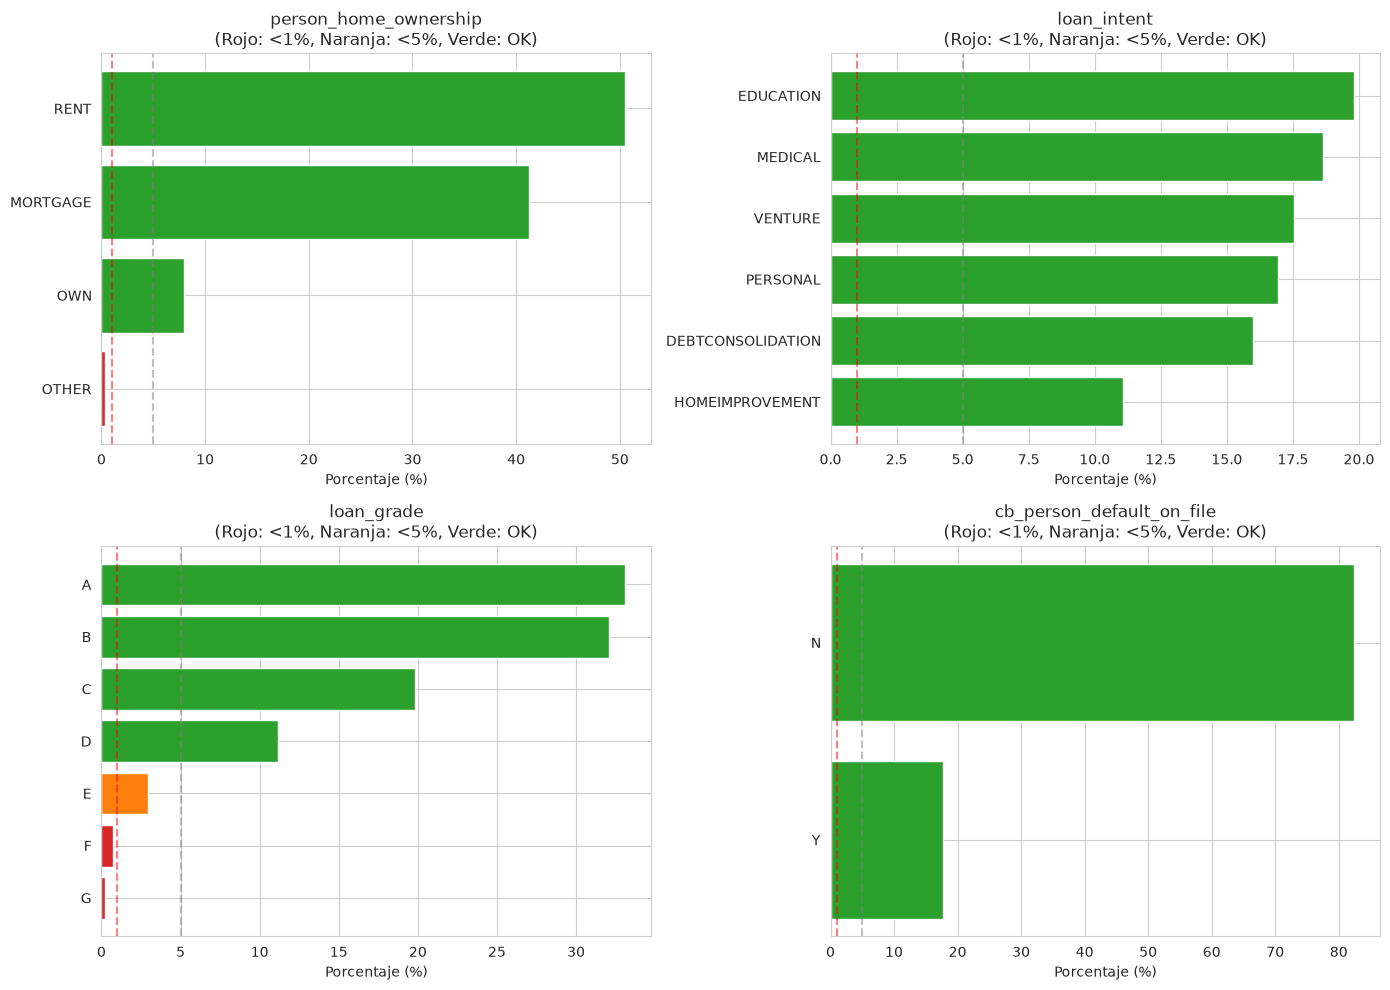

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    freq = df[col].value_counts(normalize=True) * 100
    colores = ["#d62728" if p < umbral_critico 
               else "#ff7f0e" if p < umbral_warning 
               else "#2ca02c" for p in freq.values]
    
    axes[i].barh(freq.index.astype(str), freq.values, color=colores)
    axes[i].set_xlabel("Porcentaje (%)")
    axes[i].set_title(f"{col}\n(Rojo: <1%, Naranja: <5%, Verde: OK)")
    axes[i].invert_yaxis()
    axes[i].axvline(x=5, color="gray", linestyle="--", alpha=0.5, label="Umbral 5%")
    axes[i].axvline(x=1, color="red", linestyle="--", alpha=0.5, label="Umbral 1%")

plt.tight_layout()
plt.show()

In [71]:
print("=== OPCIONES DE TRATAMIENTO ===\n")

opciones = """
OPCIÓN A — Conservar (recomendado para este proyecto)
  ✅ Ventaja: no pierdes información, el dashboard puede mostrar filtros finos.
  ⚠️ Desventaja: algunas categorías tendrán conteos bajos en gráficos.

OPCIÓN B — Agrupar rare labels en una categoría "OTROS"
  ✅ Ventaja: simplifica visualizaciones, evita barras diminutas.
  ⚠️ Desventaja: pierdes granularidad, y "OTROS" puede ser heterogéneo.

OPCIÓN C — Eliminar rare labels
  ❌ NO recomendado: perderías información y podrías sesgar la tasa de default.

OPCIÓN D — Tratar de forma especial en el dashboard
  ✅ Ventaja: mantienes el dato, pero con un filtro "mostrar categorías con n>X".
  ✅ Es lo que hacen dashboards profesionales.
"""
print(opciones)

=== OPCIONES DE TRATAMIENTO ===


OPCIÓN A — Conservar (recomendado para este proyecto)
  ✅ Ventaja: no pierdes información, el dashboard puede mostrar filtros finos.
  ⚠️ Desventaja: algunas categorías tendrán conteos bajos en gráficos.

OPCIÓN B — Agrupar rare labels en una categoría "OTROS"
  ✅ Ventaja: simplifica visualizaciones, evita barras diminutas.
  ⚠️ Desventaja: pierdes granularidad, y "OTROS" puede ser heterogéneo.

OPCIÓN C — Eliminar rare labels
  ❌ NO recomendado: perderías información y podrías sesgar la tasa de default.

OPCIÓN D — Tratar de forma especial en el dashboard
  ✅ Ventaja: mantienes el dato, pero con un filtro "mostrar categorías con n>X".
  ✅ Es lo que hacen dashboards profesionales.



### 📝 Veredicto — Categorías minoritarias (Rare labels)

**Hallazgos:**
- **4 rare labels detectadas** (frecuencia <5%):
  - `loan_grade = G`: 64 casos (0.20%) 🚩 CRÍTICO
  - `person_home_ownership = OTHER`: 107 casos (0.33%) 🚩 CRÍTICO
  - `loan_grade = F`: 241 casos (0.74%) 🚩 CRÍTICO
  - `loan_grade = E`: 964 casos (2.96%) ⚠️ Bajo
- **Filas afectadas si se eliminaran todas:** 1,376 (4.22% del dataset).
- **Impacto en tasa de default global:** bajaría de 21.82% a 19.96% (-1.86 pp).
- **🚨 Hallazgo crítico — las rare labels son los segmentos más riesgosos:**
  - `loan_grade = G`: **98.44%** de default (vs 21.82% global).
  - `loan_grade = F`: **70.54%**.
  - `loan_grade = E`: **64.42%**.
  - `person_home_ownership = OTHER`: **30.84%**.

**Análisis:**
Las rare labels de este dataset NO son ruido estadístico, sino **los segmentos de mayor riesgo**. El grado G tiene un default casi garantizado (98.44%), y eliminar estas categorías ocultaría precisamente la parte más crítica de la cartera.

En este contexto, eliminar rare labels sería un error de negocio grave: sesgaría a la baja la tasa de default global y escondería los focos de riesgo que el dashboard debería destacar.

**Decisión para el Día 2 (limpieza):**
- **Conservar TODAS las rare labels** sin agrupar ni eliminar. Son informativas y críticas para el análisis de riesgo.
- **Tratamiento visual en el dashboard (Looker Studio):**
  - Mostrar el conteo absoluto (n) junto al porcentaje en cada gráfico.
  - Agregar notas aclaratorias: *"Grado G: 64 casos, 98% de default — segmento de máxima alerta"*.
  - Opcional: ofrecer un filtro "Mostrar solo categorías con n > 100" para que el usuario controle la visualización.

**Justificación:**
En un dashboard de riesgo crediticio, el valor no está solo en los promedios, sino en identificar los segmentos extremos. Las rare labels de `loan_grade` (E, F, G) concentran las tasas de default más altas y deben permanecer visibles para informar decisiones de negocio (ej. endurecer políticas para grado G). Eliminarlas no solo perdería información, sino que crearía una falsa sensación de cartera sana.

### 2.11 MEZCLA DE UNIDADES DE MEDIDA

In [72]:
print("=== VERIFICACIÓN DE ESCALAS POR COLUMNA ===\n")

# Diccionario de unidades esperadas según el nombre de la columna
unidades_esperadas = {
    "person_age": ("años", "entero, típicamente 18-100"),
    "person_income": ("USD/año", "entero, típicamente 4K-6M"),
    "person_emp_length": ("años", "decimal, típicamente 0-40"),
    "loan_amnt": ("USD", "entero, típicamente 500-35K"),
    "loan_int_rate": ("% anual", "decimal, típicamente 5-25"),
    "loan_status": ("flag", "0 o 1"),
    "loan_percent_income": ("fracción [0,1]", "decimal, típicamente 0-1"),
    "cb_person_cred_hist_length": ("años", "entero, típicamente 0-30"),
}

for col, (unidad, rango_tipico) in unidades_esperadas.items():
    if col in df.columns:
        serie = df[col].dropna()
        print(f"{col:30}")
        print(f"  Unidad esperada: {unidad}")
        print(f"  Rango típico:    {rango_tipico}")
        print(f"  Rango real:      min={serie.min()}, max={serie.max()}, "
              f"mediana={serie.median()}")
        print()

=== VERIFICACIÓN DE ESCALAS POR COLUMNA ===

person_age                    
  Unidad esperada: años
  Rango típico:    entero, típicamente 18-100
  Rango real:      min=20, max=144, mediana=26.0

person_income                 
  Unidad esperada: USD/año
  Rango típico:    entero, típicamente 4K-6M
  Rango real:      min=4000, max=6000000, mediana=55000.0

person_emp_length             
  Unidad esperada: años
  Rango típico:    decimal, típicamente 0-40
  Rango real:      min=0.0, max=123.0, mediana=4.0

loan_amnt                     
  Unidad esperada: USD
  Rango típico:    entero, típicamente 500-35K
  Rango real:      min=500, max=35000, mediana=8000.0

loan_int_rate                 
  Unidad esperada: % anual
  Rango típico:    decimal, típicamente 5-25
  Rango real:      min=5.42, max=23.22, mediana=10.99

loan_status                   
  Unidad esperada: flag
  Rango típico:    0 o 1
  Rango real:      min=0, max=1, mediana=0.0

loan_percent_income           
  Unidad esperada: 

In [73]:
print("=== DETECCIÓN DE MEZCLA DENTRO DE COLUMNAS ===\n")

def detectar_mezcla(serie, nombre):
    """Detecta si hay dos 'poblaciones' distintas en la misma columna."""
    # Usar la mediana como punto de corte
    mediana = serie.median()
    # Dividir en dos grupos: por debajo y por encima de la mediana * 10
    pequenos = (serie < mediana / 10).sum()
    grandes = (serie > mediana * 10).sum()
    return {"columna": nombre, "pequenos": pequenos, "grandes": grandes,
            "mediana": round(mediana, 2)}

# Verificar columnas continuas
cols_continuas = ["person_income", "loan_amnt", "loan_int_rate", 
                  "loan_percent_income", "person_emp_length"]

resultados = []
for col in cols_continuas:
    serie = df[col].dropna()
    r = detectar_mezcla(serie, col)
    resultados.append(r)
    flag = "🚩" if (r["pequenos"] > 0 or r["grandes"] > 0) else "✅"
    print(f"{flag} {col:25} mediana={r['mediana']:>10} | "
          f"valores < mediana/10: {r['pequenos']:>5} | "
          f"valores > mediana*10: {r['grandes']:>5}")

# Interpretación
print("\nInterpretación:")
print("- Si hay valores < mediana/10 O > mediana*10 en proporción significativa,")
print("  podría indicar mezcla de unidades (ej. USD vs miles de USD).")
print("- En este dataset, deberíamos ver 0 en ambas columnas para todas las variables.")

=== DETECCIÓN DE MEZCLA DENTRO DE COLUMNAS ===

🚩 person_income             mediana=   55000.0 | valores < mediana/10:    10 | valores > mediana*10:    46
🚩 loan_amnt                 mediana=    8000.0 | valores < mediana/10:     8 | valores > mediana*10:     0
✅ loan_int_rate             mediana=     10.99 | valores < mediana/10:     0 | valores > mediana*10:     0
🚩 loan_percent_income       mediana=      0.15 | valores < mediana/10:   148 | valores > mediana*10:     0
🚩 person_emp_length         mediana=       4.0 | valores < mediana/10:  4105 | valores > mediana*10:     3

Interpretación:
- Si hay valores < mediana/10 O > mediana*10 en proporción significativa,
  podría indicar mezcla de unidades (ej. USD vs miles de USD).
- En este dataset, deberíamos ver 0 en ambas columnas para todas las variables.


In [74]:
print("=== COHERENCIA ENTRE COLUMNAS RELACIONADAS ===\n")

# 1. loan_amnt y person_income: el préstamo no debe ser mayor al ingreso anual
max_ratio = (df["loan_amnt"] / df["person_income"]).max()
print(f"1. Máximo loan_amnt / person_income: {max_ratio:.4f}")
print(f"   → Si >1, habría préstamos mayores al ingreso (raro pero posible).")
print(f"   → Si >>1 (ej. 100), sugiere mezcla de unidades.")

# 2. loan_int_rate y loan_percent_income: escalas distintas
print(f"\n2. loan_int_rate (debería ser 5-25): "
      f"min={df['loan_int_rate'].min():.2f}, max={df['loan_int_rate'].max():.2f}")
print(f"   loan_percent_income (debería ser 0-1): "
      f"min={df['loan_percent_income'].min():.2f}, max={df['loan_percent_income'].max():.2f}")
print(f"   → Escalas distintas: la primera en %, la segunda en fracción. ✅")

# 3. Edad y tiempo: person_age, emp_length, cred_hist deben estar en años
print(f"\n3. Escalas temporales (todas deberían ser años):")
for col in ["person_age", "person_emp_length", "cb_person_cred_hist_length"]:
    print(f"   {col:30} → max={df[col].max():.2f}")
print(f"   → Todas en rango de años (0-144). ✅")

=== COHERENCIA ENTRE COLUMNAS RELACIONADAS ===

1. Máximo loan_amnt / person_income: 0.8300
   → Si >1, habría préstamos mayores al ingreso (raro pero posible).
   → Si >>1 (ej. 100), sugiere mezcla de unidades.

2. loan_int_rate (debería ser 5-25): min=5.42, max=23.22
   loan_percent_income (debería ser 0-1): min=0.00, max=0.83
   → Escalas distintas: la primera en %, la segunda en fracción. ✅

3. Escalas temporales (todas deberían ser años):
   person_age                     → max=144.00
   person_emp_length              → max=123.00
   cb_person_cred_hist_length     → max=30.00
   → Todas en rango de años (0-144). ✅


In [75]:
print("=== OUTLIERS QUE SUGIERAN CAMBIO DE ESCALA ===\n")

# Si alguien ingresara un monto en 'miles de USD' en una columna en USD,
# ese valor sería 1000x más grande que la mediana.
# Buscar valores >100x la mediana (señal de posible mezcla de unidades).

for col in ["person_income", "loan_amnt", "loan_int_rate"]:
    serie = df[col].dropna()
    mediana = serie.median()
    sospechosos = (serie > mediana * 100).sum()
    if sospechosos > 0:
        print(f"⚠️ {col}: {sospechosos} valores > 100× la mediana")
        print(f"   Valores: {sorted(serie[serie > mediana * 100].unique())[:5]}...")
    else:
        print(f"✅ {col}: sin valores > 100× la mediana")

=== OUTLIERS QUE SUGIERAN CAMBIO DE ESCALA ===

⚠️ person_income: 1 valores > 100× la mediana
   Valores: [np.int64(6000000)]...
✅ loan_amnt: sin valores > 100× la mediana
✅ loan_int_rate: sin valores > 100× la mediana


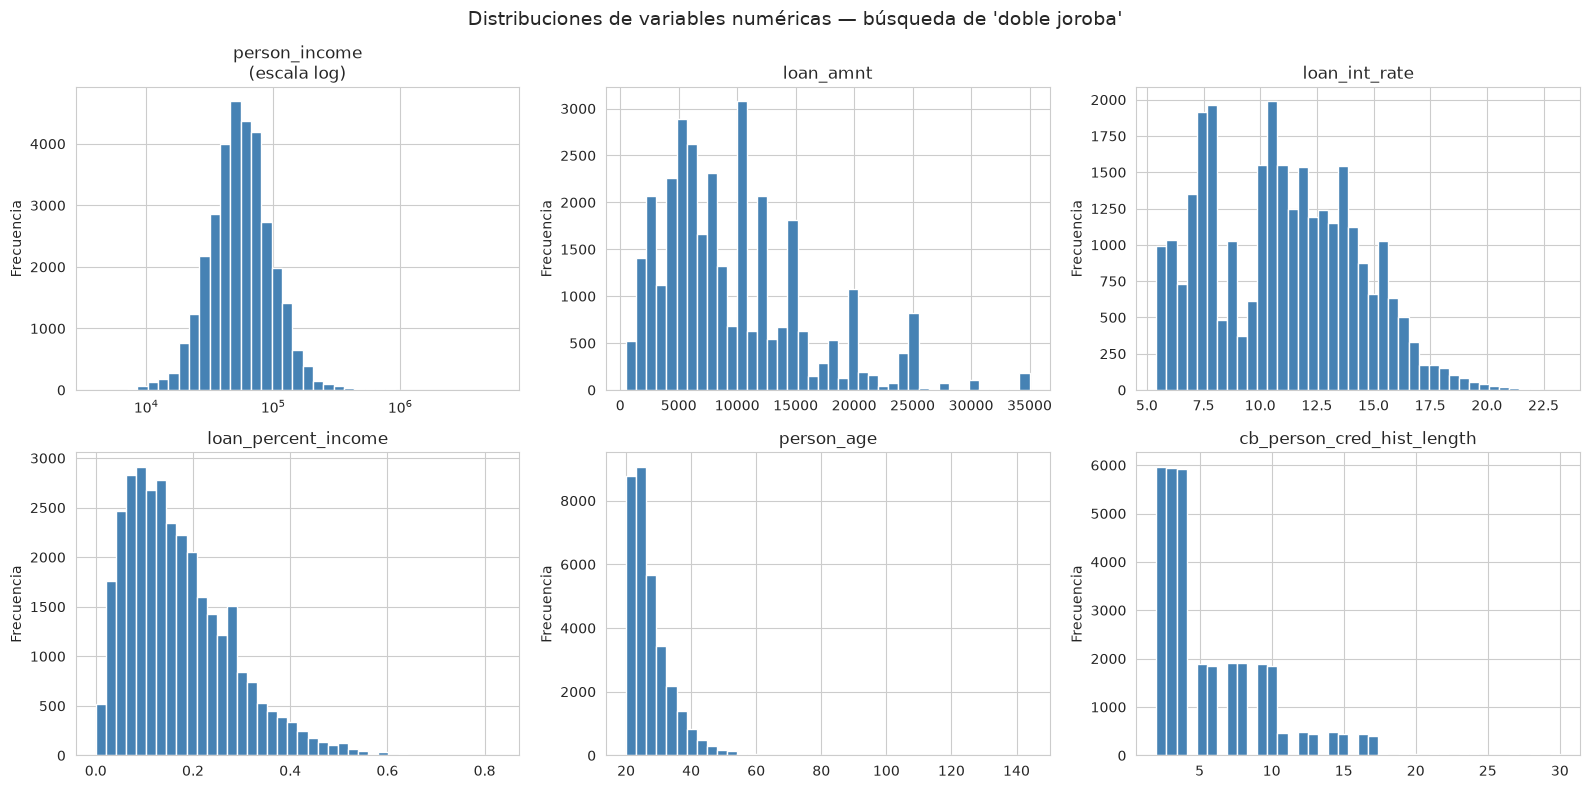

In [77]:
# Histogramas en escala logarítmica para detectar "dos jorobas" (dos poblaciones)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

cols_plot = ["person_income", "loan_amnt", "loan_int_rate", 
             "loan_percent_income", "person_age", "cb_person_cred_hist_length"]

for i, col in enumerate(cols_plot):
    serie = df[col].dropna()
    minimo = serie.min()
    maximo = serie.max()
    
    # Usar escala log SOLO si: min > 0 y el rango es amplio (>100x)
    usar_log = (minimo > 0) and (maximo / minimo > 100)
    
    if usar_log:
        bins = np.logspace(np.log10(minimo), np.log10(maximo), 40)
        axes[i].hist(serie, bins=bins, color="steelblue", edgecolor="white")
        axes[i].set_xscale("log")
        axes[i].set_title(f"{col}\n(escala log)")
    else:
        axes[i].hist(serie, bins=40, color="steelblue", edgecolor="white")
        axes[i].set_title(col)
    
    axes[i].set_ylabel("Frecuencia")

plt.suptitle("Distribuciones de variables numéricas — búsqueda de 'doble joroba'", fontsize=14)
plt.tight_layout()
plt.show()

### 📝 Veredicto — Mezcla de unidades de medida

**Hallazgos:**

| Columna | Unidad | Rango real | Coherente |
|---------|--------|------------|-----------|
| person_age | años | 20–144 | ✅ |
| person_income | USD/año | 4,000–6,000,000 | ✅ |
| person_emp_length | años | 0–123 | ✅ |
| loan_amnt | USD | 500–35,000 | ✅ |
| loan_int_rate | % anual | 5.42–23.22 | ✅ |
| loan_status | flag | 0 o 1 | ✅ |
| loan_percent_income | fracción | 0–0.83 | ✅ |
| cb_person_cred_hist_length | años | 2–30 | ✅ |

- **Mezcla dentro de columnas:** no detectada. Los indicadores del método automático (`mediana/10` y `mediana*10`) son **falsos positivos** explicables por las colas naturales de cada distribución y por valores legítimos de 0 (`person_emp_length = 0` para desempleados, `loan_percent_income = 0` para préstamos mínimos relativos al ingreso).
- **Coherencia entre columnas relacionadas:** `loan_amnt / person_income` máximo = 0.83 → nadie pide más de su ingreso anual.
- **Outliers > 100× mediana:** solo 1 caso en `person_income` ($6M) — ya catalogado como outlier plausible en la Situación 4.
- **Distribuciones:** todas unimodales. Sin evidencia de "doble joroba" (dos poblaciones mezcladas).

**Análisis:**
El dataset usa unidades de medida consistentes. Cada columna mantiene una escala única internamente: años para variables temporales, USD para montos, porcentaje para tasas, fracción para proporciones. Las aparentes "mezclas" detectadas por el método automático son el resultado esperado de distribuciones asimétricas con colas largas, no de errores de unidades.

**Decisión para el Día 2 (limpieza):**
- **Sin acciones necesarias.**
- Documentar las unidades en el README y en las vistas SQL para claridad:
  - `loan_int_rate`: en porcentaje (5.42–23.22, no multiplicar por 100).
  - `loan_percent_income`: en fracción (0–0.83, multiplicar por 100 para mostrar %).

**Justificación:**
La mezcla de unidades es un error silencioso que rompe agregaciones sin dar error de tipo. En este dataset, verificar escalas, coherencia entre columnas relacionadas, y forma de las distribuciones confirma que todas las columnas usan una única unidad consistente. Es un dataset limpio también en esta dimensión.

## 🎯 Conclusiones del EDA

Se auditaron 11 dimensiones de calidad de datos sobre 32,581 solicitudes de crédito:

**Dimensiones limpias (7/11):** columnas irrelevantes, typos categóricas, tipos de datos, espacios ocultos, formato/estandarización, mezcla de unidades, y valores vacíos.

**Dimensiones con hallazgos (4/11):**
- **Nulos:** 2 columnas afectadas (12.10% de filas). MCAR verificado. Estrategia: imputación simple.
- **Duplicados:** 165 exactos + 6,128 parciales. **Sesgo detectado:** -10.41 pp en tasa de default.
- **Outliers:** 7 filas imposibles + 781 con historial crediticio inconsistente.
- **Lógica de negocio:** patrón determinista de default previo → grado C+.

**Total de filas a limpiar en el Día 2:** 144 (0.44%) + 781 caps.

**Hallazgos de negocio para el dashboard:**
- Grado G: 98.44% de default (segmento crítico con solo 64 casos).
- Punto de quiebre C→D: la tasa de default se multiplica por 2.85×.
- Default previo: regla no documentada del banco, piso de riesgo en grado C.
- `loan_grade` es el predictor más fuerte de default.

El dataset es apto para construir un dashboard de riesgo crediticio. Las limitaciones (sesgo en duplicados, historial crediticio inconsistente) se documentarán en el README y se tratarán quirúrgicamente en la fase de limpieza.

# 📊 Resumen Ejecutivo — Análisis Exploratorio (EDA)

## 🎯 Objetivo

Auditar 11 dimensiones de calidad de datos sobre **32,581 solicitudes de crédito** (12 columnas) antes de cargarlas a BigQuery y construir el dashboard de riesgo en Looker Studio.

---

## 📋 Tabla consolidada de las 11 auditorías

| # | Situación | Hallazgos | Acción para el Día 2 |
|---|-----------|-----------|----------------------|
| 1 | **Nulos** | `loan_int_rate` (9.56%), `person_emp_length` (2.75%). Verificado: MCAR (aleatorios). | Imputar: mediana + 0 |
| 2 | **Columnas irrelevantes** | Ninguna. Correlación `person_age` ↔ `cb_person_cred_hist_length` (r=0.86) pero **no redundante**. | Conservar las 12 |
| 3 | **Duplicados** | 165 exactos + 6,128 parciales. **Sesgo crítico: -10.41 pp en tasa de default**. | Eliminar 137, crear `n_solicitudes_cliente` |
| 4 | **Outliers** | 5 filas con edad 123-144. 2 filas con empleo 123 años. **781 filas con historial crediticio inconsistente**. | Eliminar 7, cap 781 |
| 5 | **Typos categóricas** | Todo limpio. 3 rare labels anotadas. | Sin acciones |
| 6 | **Tipos de datos** | Todos correctos. Sin falsos textos. | Sin acciones |
| 7 | **Espacios ocultos** | Todo limpio (6 verificaciones: leading/trailing, tabulaciones, Unicode invisible, dobles espacios). | Sin acciones |
| 8 | **Inconsistencias de formato** | Todos los nombres en `snake_case`. Unidades documentadas: `loan_int_rate` en % y `loan_percent_income` en fracción. | Sin acciones, documentar |
| 9 | **Lógica de negocio** | Patrón determinista: default previo → grado C+ (0 casos en A/B). Salto C→D (20.73% → 59.05%). Grado G: 98.44% default. | Documentar como insight |
| 10 | **Rare labels** | 4 rare labels, pero son los **segmentos MÁS riesgosos**. | Conservar todas |
| 11 | **Mezcla de unidades** | Todas consistentes. Distribuciones unimodales (sin doble joroba). | Sin acciones |

---

## 🎯 Acciones consolidadas para el Día 2 (Limpieza)

| Acción | Filas afectadas | % del dataset |
|--------|-----------------|---------------|
| Eliminar duplicados exactos (conservar primera ocurrencia) | 137 | 0.42% |
| Eliminar edades imposibles (`person_age > 100`) | 5 | 0.02% |
| Eliminar historial laboral imposible (`emp_length > age - 14`) | 2 | 0.01% |
| Cap de historial crediticio inconsistente: `min(actual, age - 18)` | 781 | 2.40% |
| Imputar `loan_int_rate` con la mediana (9.56% nulos) | 3,116 | 9.56% |
| Imputar `person_emp_length` con 0 (2.75% nulos) | 895 | 2.75% |
| **Crear columna nueva** `n_solicitudes_cliente` | 32,581 | 100% |
| **Total filas a eliminar** | **144** | **0.44%** |
| **Total filas finales estimadas** | **~32,437** | — |

---

## 🏆 Los 3 hallazgos estrella

### 🥇 Sesgo en duplicados (Situación 3)

Los duplicados del dataset **no son aleatorios**: tienen una tasa de default de **11.52%** frente al **21.92%** de las filas únicas. Diferencia: **-10.41 puntos porcentuales**. Esto indica que la duplicación está correlacionada con la variable objetivo — un hallazgo que impacta directamente el cálculo agregado de la tasa de default en el dashboard.

### 🥈 Patrón determinista de default previo (Situación 9)

De las **5,745 personas con default previo** en buró, **cero recibieron grado A o B**. Todas fueron asignadas a grado C o peor. Esto revela una regla de negocio no documentada: el banco aplica un "piso de riesgo" basado en el historial. `cb_person_default_on_file` es un predictor extremadamente fuerte.

### 🥉 Rare labels = segmentos más riesgosos (Situación 10)

Los rare labels no son ruido: son precisamente los **focos de mayor riesgo**:

| Rare label | Frecuencia | Tasa de default |
|------------|-----------|-----------------|
| `loan_grade = G` | 0.20% (64 casos) | **98.44%** |
| `loan_grade = F` | 0.74% (241 casos) | **70.54%** |
| `loan_grade = E` | 2.96% (964 casos) | **64.42%** |
| `person_home_ownership = OTHER` | 0.33% (107 casos) | **30.84%** |

Eliminarlos habría reducido artificialmente la tasa de default global en 1.86 pp, escondiendo el riesgo real de la cartera.

---

## 📈 Insights de negocio para el dashboard

- **`loan_grade` es el predictor más fuerte de default.** La tasa crece monotónicamente de A (9.96%) a G (98.44%).
- **Punto de quiebre C→D:** entre el grado C (20.73%) y el D (59.05%), la tasa se multiplica por **2.85×**. Segmentación natural: "buenos" (A/B/C) vs "malos" (D/E/F/G).
- **Default previo → grado C+:** regla del banco. Útil para entender por qué `cb_person_default_on_file = Y` es un filtro clave en el dashboard.
- **Nadie pide préstamos mayores a su ingreso anual** (máximo `loan_amnt / person_income` = 0.83). El 12.36% pide más del 30% de su ingreso — segmento de sobreendeudamiento a monitorear.

---

## ✅ Veredicto final del EDA

El dataset es **apto para construir el dashboard de riesgo crediticio**. Se auditaron 11 dimensiones de calidad:

- **7 dimensiones limpias:** columnas irrelevantes, typos categóricas, tipos de datos, espacios ocultos, formato/estandarización, mezcla de unidades, valores vacíos.
- **4 dimensiones con hallazgos:** nulos (2 columnas), duplicados (con sesgo), outliers (7 imposibles + 781 a corregir), lógica de negocio (patrón determinista).

Las correcciones necesarias son **quirúrgicas**: solo se eliminará el **0.44% de las filas** y se aplicará un cap a 781 filas. El volumen del dataset se preserva (99.56% de los datos se mantienen).

Las limitaciones detectadas (sesgo en duplicados, historial crediticio inconsistente) se documentarán explícitamente en el README para que cualquier lector del dashboard conozca el contexto de los datos.

---

## 🎯 Siguiente fase

**Día 2 — Limpieza (`02_limpieza.ipynb`):** aplicar las decisiones de la tabla consolidada, guardar el CSV limpio como `data/credit_risk_clean.csv`, y verificar que las 11 dimensiones quedan resueltas tras la limpieza.